 # Predictive Maintenance: Machine Failure Classification



 > **Term project:** A Comparative Study of Feature Reduction Strategies and Machine Learning Classifiers for Industrial Fault Detection



 ## 1. Project Objective|



 This project investigates whether selecting a smaller set of machine sensors can produce a useful classifier for the `Machine failure` target in the AI4I 2020 predictive-maintenance dataset. The primary metric is positive-class failure F1, supported by failure recall, precision, balanced accuracy, missed failures, and false alarms.



 ## 2. Experiment Roadmap



 The notebook follows one fixed workflow from start to finish:



 1. **Load and explore the data.** Inspect columns, data types, missing values, duplicates, class balance, and simple relationships.

 2. **Prepare predictors and target.** Keep the 6 usable raw sensor variables, encode `Type`, and exclude identifiers and failure-cause columns that would leak the target.

 3. **Create fixed data splits.** Use stratified 70% training, 15% validation, and 15% test splits. The test split is hidden until the final step.

 4. **Configure experiment settings.** Set the number of selected features, selector models, PCA variance threshold, and cross-validation folds in one place.

 5. **Fit feature-selection methods on training data only.** Compare ANOVA, Pearson correlation, adapted Lasso, RFE, forward/backward selection, and PCA.

 6. **Screen model combinations.** Fit the baseline and selected-feature models on training data and compare them on validation data.

 7. **Choose three finalists & test Stacking.** Select the top three distinct model architectures using validation failure F1, recall, and precision, and test whether combining them into a Stacking Ensemble improves performance.

 8. **Fine-tune finalists.** Search focused hyperparameter grids using five-fold stratified cross-validation on the training split.

 9. **Choose the tuned winner & refit.** Compare the tuned finalists on validation performance, then refit the winning configuration on the combined training and validation data (85%).

 10. **Evaluate once on the test set.** Report the final unseen-data result, confusion matrix, ROC & AUC curve, missed failures, and false alarms.



 ## 3. Important Interpretation Rule



 The validation tables answer **which approach should be selected**. The final test table answers **how the already-selected approach performs on unseen data**. A test score must not be used to choose a different winner.

## Notebook Contents

Use these links to jump to a section or a key step within it.

- [1. Project Objective](#1-project-objective)
- [2. Experiment Roadmap](#2-experiment-roadmap)
- [3. Important Interpretation Rule](#3-important-interpretation-rule)
- [4. Load Data](#4-load-data)
- [5. Explore](#5-explore)
  - [Additional EDA: failure patterns and sensor relationships](#additional-eda-failure-patterns-and-sensor-relationships)
  - [EDA plots and interpretation](#eda-plots)
- [6. Pre-processing and Data Splitting](#6-pre-processing-and-data-splitting)
- [7. Master Experiment Configuration](#7-master-experiment-configuration)
- [8. Modelling and Evaluation Setup](#8-modelling-and-evaluation-setup)
  - [Experimental Rules & Metrics](#81-experimental-rules-metrics)
- [9. No Feature Selection: Baseline](#9-no-feature-selection-baseline)
- [10. Filter Methods](#10-filter-methods)
  - [ANOVA F-Test Filter Selection](#101-anova-f-test-filter-selection)
  - [Pearson Correlation Selection](#102-pearson-correlation-selection)
- [11. Embedded Methods (Regularization)](#11-embedded-methods-regularization)
  - [Adapted Lasso (L1) Selection](#111-adapted-lasso-l1-selection)
  - [Ridge, Lasso, and Elastic Net Comparison](#112-ridge-l2-lasso-l1-and-elastic-net-comparison)
- [12. Wrapper Methods](#12-wrapper-methods)
  - [Recursive Feature Elimination (RFE)](#121-recursive-feature-elimination-rfe)
  - [Forward and Backward Sequential Feature Selection](#122-forward-and-backward-sequential-feature-selection-sfs)
- [13. Dimensionality Reduction](#13-dimensionality-reduction)
  - [Principal Component Analysis (PCA)](#131-principal-component-analysis-pca)
- [14. Validation Comparison and Candidate Screening](#14-validation-comparison-and-candidate-screening)
  - [Feature-selection comparison plot](#interpreting-the-feature-selection-comparison)
  - [Selecting the Top Three Finalists](#141-selecting-the-top-three-finalists-deduplicating-identical-sensor-subsets)
- [15. Stacking Ensemble Validation Check](#15-new-stacking-ensemble-experiment-standalone-validation-check-below-at-17)
- [16. Fine-Tune the Top Three Finalists](#16-fine-tune-the-top-three-finalists-5-fold-cross-validation)
  - [Finalist model comparison plot](#interpreting-the-tuned-finalist-comparison)
  - [Select the Final Tuned Winner](#161-select-the-final-tuned-winner)
  - [Winning-model feature importance](#interpreting-winning-model-feature-importance)
  - [Precision-recall curve](#interpreting-the-precision-recall-curve)
  - [Refit on the 85% Development Data](#162-refit-on-the-85-development-data)
- [17. Final Test Evaluation](#17-final-test-evaluation-tuned-single-winner-vs-stacking-ensemble)
- [18. Term Project Conclusion and Recommendations](#18-term-project-conclusion-and-recommendations)
- [19. Experiment Run Logger and Summary Exporter](#19-experiment-run-logger-summary-exporter)

 ## 4. Load Data

In [11]:
# Reproducibility and common imports
import os
import random

RANDOM_STATE = 55
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

np.random.seed(RANDOM_STATE)


In [12]:
# %pip install kagglehub[pandas-datasets]
# %pip show kagglehub

In [13]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "ai4i2020.csv"

# Load the latest version
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
    file_path,
)

print("First 5 records:")
display(df.head())


First 5 records:


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


 ## 5. Explore



 Inspect the AI4I 2020 predictive-maintenance dataset structure, data types, missing values, duplicates, class balance, and physical sensor relationships.

In [14]:
display(df.columns)


Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [15]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [16]:
print(df["Type"])


0       M
1       L
2       L
3       L
4       L
       ..
9995    M
9996    H
9997    M
9998    H
9999    M
Name: Type, Length: 10000, dtype: object


In [17]:
display(df)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [18]:
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate UDIs:", df["UDI"].duplicated().sum())


Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicate rows: 0
Duplicate UDIs: 0


Machine failure
0    9661
1     339
Name: count, dtype: int64 
 Machine failure
0    96.61
1     3.39
Name: count, dtype: float64


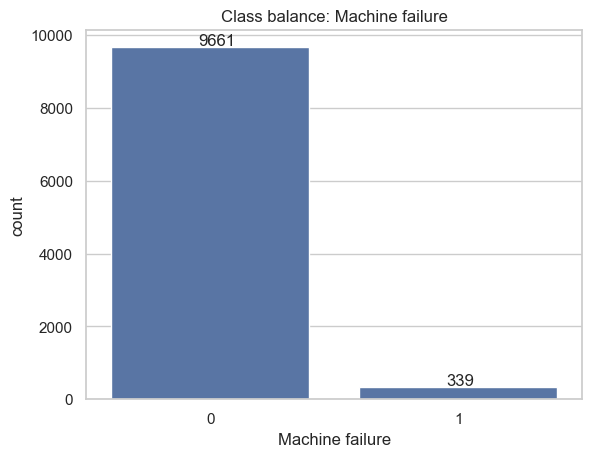

In [19]:
counts = df["Machine failure"].value_counts()
print(counts, "\n", (counts / len(df) * 100).round(2))

ax = sns.countplot(x="Machine failure", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + 0.35, p.get_height() + 50))
plt.title("Class balance: Machine failure")
plt.show()


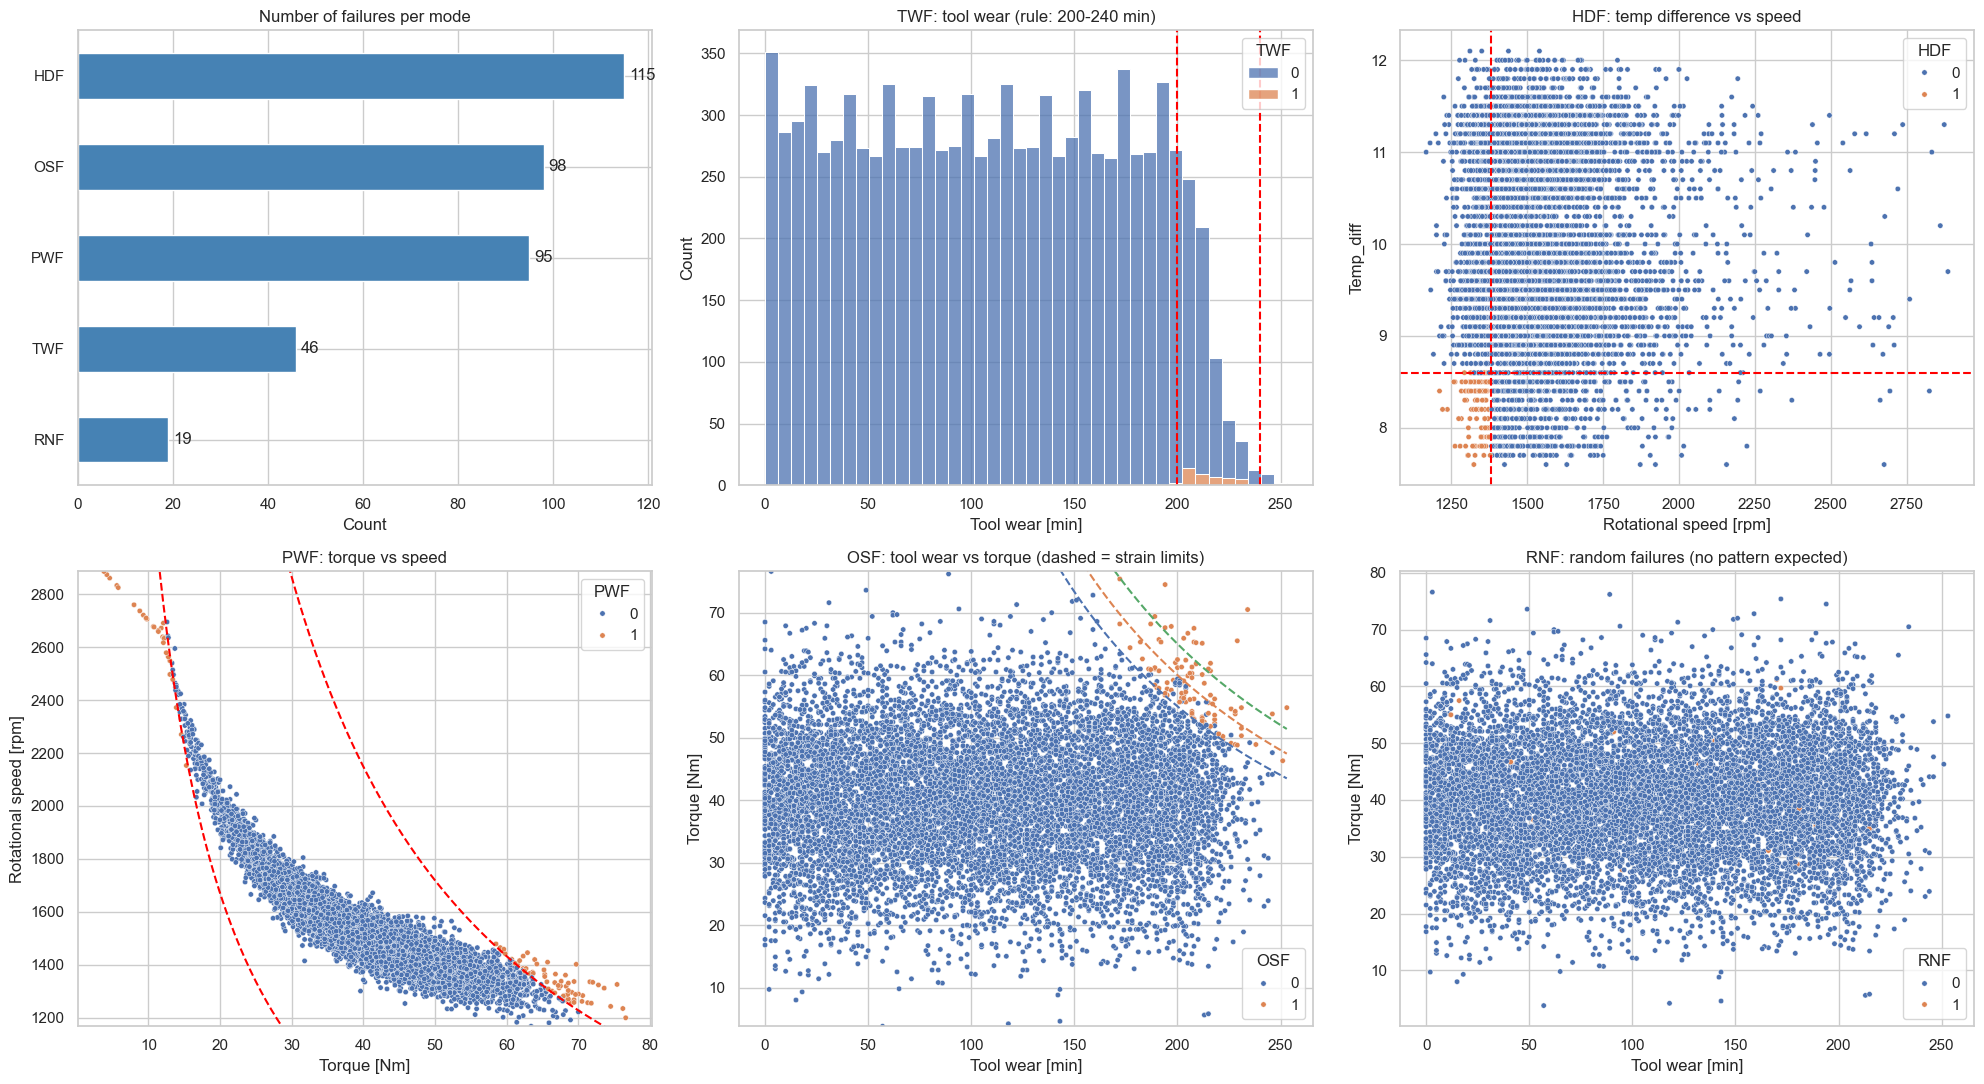

In [20]:
sns.set_theme(style="whitegrid")

# Original column names (used for EDA visualization only)
air, proc = "Air temperature [K]", "Process temperature [K]"
rpm, tq, wear = "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Temporary helper columns for plotting physical failure boundaries in EDA
eda_df = df.copy()
eda_df["Temp_diff"] = eda_df[proc] - eda_df[air]
eda_df["Power"] = eda_df[tq] * eda_df[rpm] * 2 * np.pi / 60
eda_df["Strain"] = eda_df[wear] * eda_df[tq]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()

# 1) Count of each failure mode
mode_counts = eda_df[modes].sum().sort_values()
mode_counts.plot(kind="barh", ax=axes[0], color="steelblue")
for i, v in enumerate(mode_counts):
    axes[0].text(v + 1, i, int(v), va="center")
axes[0].set_title("Number of failures per mode")
axes[0].set_xlabel("Count")

# 2) TWF: tool wear (failures expected between 200 and 240 min)
sns.histplot(data=eda_df, x=wear, hue="TWF", bins=40, multiple="stack", ax=axes[1])
axes[1].axvline(200, color="red", ls="--")
axes[1].axvline(240, color="red", ls="--")
axes[1].set_title("TWF: tool wear (rule: 200-240 min)")

# 3) HDF: temperature difference < 8.6 K and speed < 1380 rpm
sns.scatterplot(data=eda_df, x=rpm, y="Temp_diff", hue="HDF", s=15, ax=axes[2])
axes[2].axhline(8.6, color="red", ls="--")
axes[2].axvline(1380, color="red", ls="--")
axes[2].set_title("HDF: temp difference vs speed")

# 4) PWF: power < 3500 W or > 9000 W
sns.scatterplot(data=eda_df, x=tq, y=rpm, hue="PWF", s=15, ax=axes[3])
axes[3].set_title("PWF: torque vs speed")
axes[3].set_ylim(eda_df[rpm].min(), eda_df[rpm].max())
t = np.linspace(max(eda_df[tq].min(), 1), eda_df[tq].max(), 300)
for P in (3500, 9000):
    axes[3].plot(t, P * 60 / (2 * np.pi * t), color="red", ls="--")

# 5) OSF: strain above 11000 (L), 12000 (M), 13000 (H)
sns.scatterplot(data=eda_df, x=wear, y=tq, hue="OSF", s=15, ax=axes[4])
w = np.linspace(max(eda_df[wear].min(), 1), eda_df[wear].max(), 300)
for lim in (11000, 12000, 13000):
    axes[4].plot(w, lim / w, ls="--", label=f"{lim}")
axes[4].set_ylim(eda_df[tq].min(), eda_df[tq].max())
axes[4].set_title("OSF: tool wear vs torque (dashed = strain limits)")

# 6) RNF: random by design, so no rule region is expected
sns.scatterplot(data=eda_df, x=wear, y=tq, hue="RNF", s=15, ax=axes[5])
axes[5].set_title("RNF: random failures (no pattern expected)")

plt.tight_layout()
plt.show()


In [21]:
print(np.unique(df["Machine failure"]))


[0 1]


### Additional EDA: failure patterns and sensor relationships

These summaries and plots examine whether failure prevalence differs by product type, how physical sensor readings vary between failed and non-failed machines, and how the sensor variables relate to one another. Failure-cause columns are excluded because they are not model input features.

,failures,machines,failure_rate_pct
Type,,,
H,21,1003,2.09
L,235,6000,3.92
M,83,2997,2.77


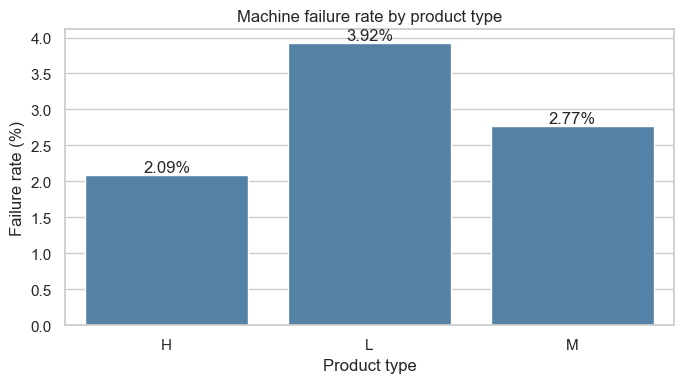

Air temperature [K]              Process temperature [K]  \
                               mean median   std                    mean   
Machine failure                                                            
No failure                   299.97  300.0  1.99                  310.00   
Failure                      300.89  301.6  2.07                  310.29   

                             Rotational speed [rpm]                  \
                median   std                   mean  median     std   
Machine failure                                                       
No failure       310.0  1.49                1540.26  1507.0  167.39   
Failure          310.4  1.36                1496.49  1365.0  384.94   

                Torque [Nm]               Tool wear [min]                
                       mean median    std            mean median    std  
Machine failure                                                          
No failure            39.63   39.9   9.47          106.69  107.0  62.95  
Failure               50.17   53.7  16.37          143.78  165.0  72.76

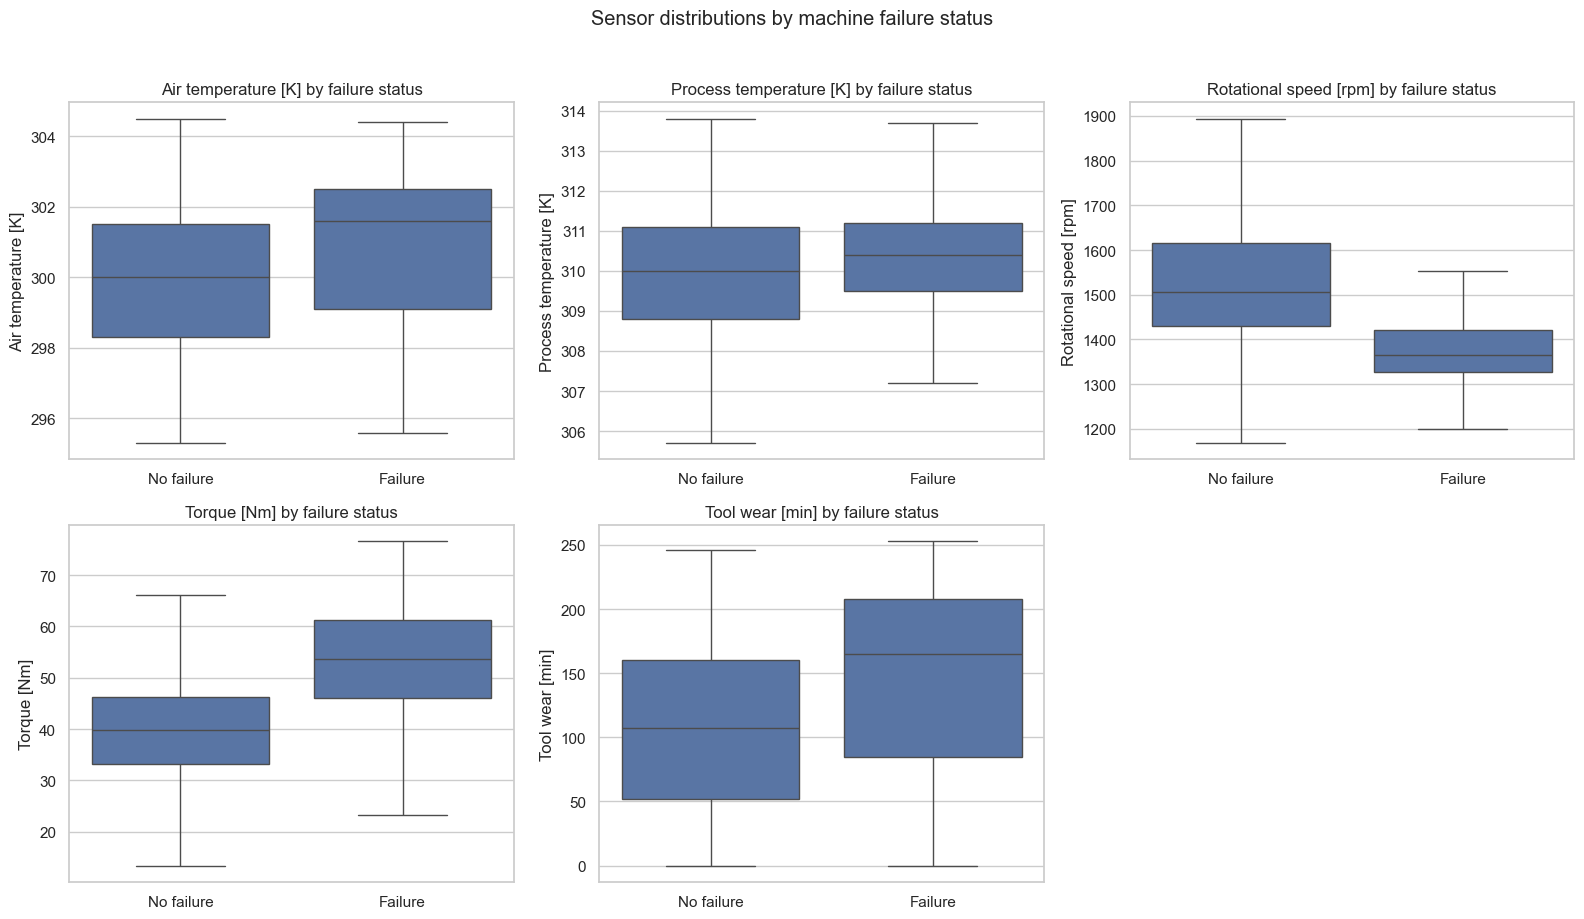

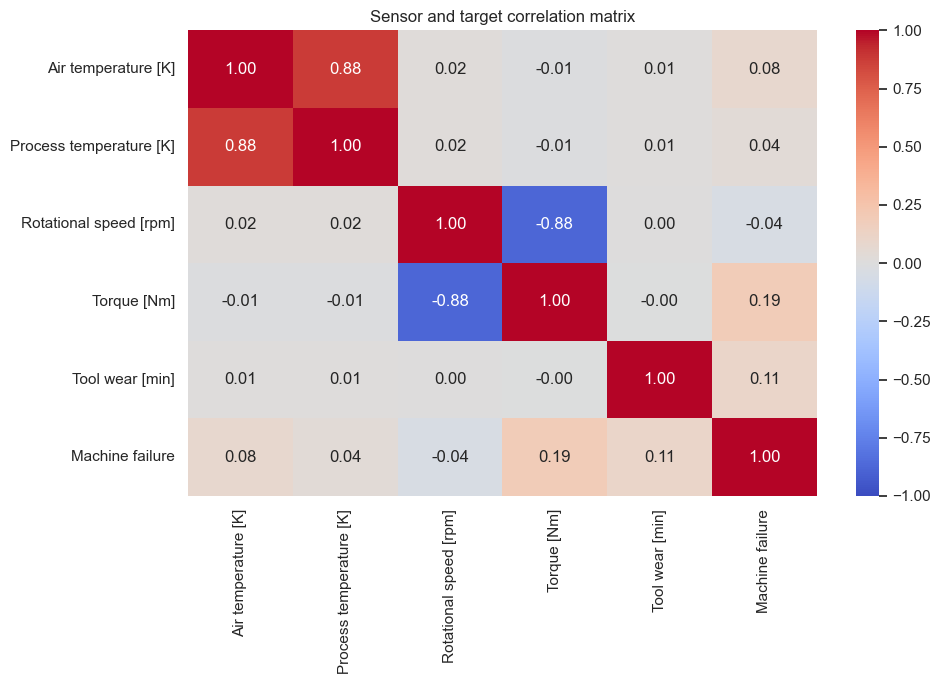

In [22]:
# Compare failure counts and rates by product type.
# Rates are more informative than counts when group sizes differ.
failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .agg(failures="sum", machines="count", failure_rate="mean")
)
failure_by_type["failure_rate_pct"] = failure_by_type["failure_rate"] * 100

display(failure_by_type[["failures", "machines", "failure_rate_pct"]].round(2))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    x=failure_by_type.index,
    y=failure_by_type["failure_rate_pct"],
    color="steelblue",
    ax=ax,
)
for bar, rate in zip(ax.patches, failure_by_type["failure_rate_pct"]):
    ax.annotate(
        f"{rate:.2f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
    )
ax.set(title="Machine failure rate by product type", xlabel="Product type", ylabel="Failure rate (%)")
plt.tight_layout()
plt.show()

# Compare the distributions of the five physical sensor measurements by target.
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
plot_df = df[sensor_features].copy()
plot_df["Failure status"] = df["Machine failure"].map({0: "No failure", 1: "Failure"})
status_order = ["No failure", "Failure"]

display(
    df.groupby("Machine failure")[sensor_features]
    .agg(["mean", "median", "std"])
    .round(2)
    .rename(index={0: "No failure", 1: "Failure"})
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, sensor_features):
    sns.boxplot(
        data=plot_df,
        x="Failure status",
        y=feature,
        order=status_order,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(f"{feature} by failure status")
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Sensor distributions by machine failure status", y=1.02)
plt.tight_layout()
plt.show()

# Pearson correlations are descriptive and do not imply causation.
correlation_features = sensor_features + ["Machine failure"]
correlation_matrix = df[correlation_features].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Sensor and target correlation matrix")
plt.tight_layout()
plt.show()

### EDA plots :

**Failure rate by product type.** The table reports both the number of failures and the number of machines in each type. The bar chart compares the percentage of machines that failed within each type, which is more informative than comparing raw failure counts when group sizes differ. A higher observed rate would indicate an association in this dataset, not that product type itself causes failure.

**Sensor distributions by failure status.** The boxplots compare the five physical sensor measurements for machines labeled as failed and not failed. The center line is the median, and the box shows the interquartile range (the middle 50% of observations). Whiskers show the remaining spread under the plotting convention; outlier points are hidden to keep the plots readable. Separation between groups may suggest a feature is associated with failure, while overlap shows that the feature alone does not perfectly distinguish the classes. The accompanying table provides mean, median, and standard deviation for additional context.

**Correlation heatmap.** Each cell shows the Pearson correlation between a pair of sensor measurements or between a sensor measurement and the binary machine-failure label. Values closer to -1 or 1 indicate stronger linear association; values near 0 indicate weaker linear association. Since failure is rare and binary, these values are descriptive and may not capture nonlinear patterns. Correlation does not establish causation, and a weak correlation does not necessarily mean a feature has no predictive value.

Taken together, these plots describe patterns in the dataset and help motivate further analysis. They do not measure model performance. The failure-cause columns are intentionally excluded from these plots because they are not valid input features for predicting the overall machine-failure label.

 ## 6. Pre-processing and Data Splitting



 Select the 6 usable raw predictor columns, encode machine `Type` (`L=0, M=1, H=2`), define the target, and create fixed stratified training (70%), validation (15%), and test (15%) splits. Identifiers (`UDI`, `Product ID`) and failure-cause columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are excluded so they cannot leak the target label.

In [23]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

x = df[features].copy()
y = df["Machine failure"]
print("Predictor shape:", x.shape)
print("Target shape:   ", y.shape)


Predictor shape: (10000, 6)
Target shape:    (10000,)


In [24]:
# Encode ordinal quality type from string to integer
x["Type"] = x["Type"].map({"L": 0, "M": 1, "H": 2})
display(x.head())


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,1,298.1,308.6,1551,42.8,0
1,0,298.2,308.7,1408,46.3,3
2,0,298.1,308.5,1498,49.4,5
3,0,298.2,308.6,1433,39.5,7
4,0,298.2,308.7,1408,40.0,9


In [25]:
print("Unique Type values:", x["Type"].unique())
print(x.dtypes)
print("Missing values:\n", x.isna().sum())


Unique Type values: [1 0 2]
Type                         int64
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object
Missing values:
 Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64


In [26]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

# Keep the test set untouched until the final evaluation.
x_train, x_temp, y_train, y_temp = train_test_split(
    x,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)
x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp,
)

print(f"Training samples:   {len(x_train)}")
print(f"Validation samples: {len(x_val)}")
print(f"Test samples:       {len(x_test)}")


Training samples:   7000
Validation samples: 1500
Test samples:       1500


In [27]:
# Check class balance in the development splits. The test labels remain unused until final evaluation.
display(
    pd.DataFrame({
        "Training": y_train.value_counts(),
        "Validation": y_val.value_counts(),
    }).fillna(0).astype(int)
)


,Training,Validation
Machine failure,,
0,6763,1449
1,237,51


 ## 7. Master Experiment Configuration



 Change the variables in the cell below and re-run the notebook to test different feature counts, RFE/SFS wrapper selectors, PCA variance thresholds, or finalist selection rules.

In [28]:
# ── Master Experiment Configuration ──────────────────────────────────
# Note: RANDOM_STATE = 55 is already set in Section 4 and shared across the notebook.
# Note: All configurations below are used to control the behavior of the experiment.
# # ─────────────────────────────────────────────────────────────────────
# # ─────────────────────────────────────────────────────────────────────

NUMBER_OF_FEATURES = 4           # Features kept by ANOVA / Correlation / Lasso / RFE / SFS (out of 6)

RFE_SELECTOR_MODEL = "Logistic Regression"
# Options: "Logistic Regression", "Linear SVC", "Decision Tree", "Random Forest"

SFS_SELECTOR_MODEL = "Decision Tree"
# Options: "Logistic Regression", "Decision Tree", "Random Forest"
# (Tip: "Decision Tree" or "Logistic Regression" runs much faster than 200-tree "Random Forest")

PCA_VARIANCE = 0.95               # Cumulative training variance PCA must retain
CV_FOLDS     = 5                  # Folds for GridSearchCV and SFS

UNIQUE_FINALIST_MODELS = False   # True  -> Top 3 finalists must be 3 distinct model architectures
                                    # False -> Allow same model architecture with different feature sets
                                    
#──────────────────────────────────────────────────────────────────────

# NUMBER_OF_FEATURES = 3
# RFE_SELECTOR_MODEL = "Random Forest"
# SFS_SELECTOR_MODEL = "Decision Tree"
# PCA_VARIANCE = 0.95
# CV_FOLDS = 5
# UNIQUE_FINALIST_MODELS = True

# Consistent sort order for ALL validation comparison tables
PRIMARY_SORT_METRICS = [
    "Validation failure F1",
    "Validation failure recall",
    "Validation failure precision",
    "Validation accuracy",
]


 ## 8. Modelling and Evaluation Setup



 The baseline classifiers compared across every feature-selection strategy are:



 - **Support Vector Classifier (SVC)** (using RBF kernel for baseline screening; Linear, Poly, and RBF tested in tuning)

 - **Logistic Regression**

 - **Decision Tree** (Gini impurity)

 - **Random Forest** (Bagging ensemble)

 - **Gradient Boosting Classifier** (Boosting ensemble)

 - **Neural Network MLP** (Multilayer Perceptron)



 *(Note: **Stacking Ensemble** is evaluated dynamically in Section 15 by combining the Top 3 screening models).*



 ### 8.1 Experimental Rules & Metrics

 - **No feature selection** (all 6 sensors) is the reference baseline.

 - Filter, Embedded, and Wrapper methods retain `NUMBER_OF_FEATURES` sensors so the screening comparison is controlled.

 - All feature selectors and scalers are fitted on **training data only** (`x_train`).

 - Because machine failures are rare (3.39%), accuracy is misleading. All tables are ranked by `PRIMARY_SORT_METRICS`:

   1. **Validation failure F1** (balance between precision and recall)

   2. **Validation failure recall** (minimizing missed failures / false negatives)

   3. **Validation failure precision** (minimizing false alarms / false positives)

   4. **Validation accuracy** (tie-breaker)

In [29]:
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, StackingClassifier
from sklearn.feature_selection import RFE, SelectKBest, SequentialFeatureSelector, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

selection_models = {
    "SVC": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000, random_state=RANDOM_STATE),
    ),
}

def evaluate_selected_features(selection_name, selected_features):
    """Fit all screening models on x_train[selected_features] and evaluate on x_val."""
    selected_features = [col for col in x_train.columns if col in selected_features] 
    rows = []
    for model_name, model in selection_models.items():
        fitted_model = clone(model)
        fitted_model.fit(x_train[selected_features], y_train)
        predictions = fitted_model.predict(x_val[selected_features])
        report = classification_report(
            y_val, predictions, output_dict=True, zero_division=0
        )
        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()
        rows.append({
            "Feature selection": selection_name,
            "Features": ", ".join(selected_features),
            "Model": model_name,
            "Validation accuracy": report["accuracy"],
            "Validation balanced accuracy": balanced_accuracy_score(y_val, predictions),
            "Validation failure precision": report["1"]["precision"],
            "Validation failure recall": report["1"]["recall"],
            "Validation failure F1": report["1"]["f1-score"],
            "Validation missed failures": fn,
            "Validation false alarms": fp,
        })
    return pd.DataFrame(rows)


 ## 9. No Feature Selection: Baseline



 Evaluate all 6 models using all 6 original sensor predictors. This serves as our benchmark before removing any features.

In [30]:
baseline_results = evaluate_selected_features(
    "No feature selection", x_train.columns.tolist()
)
display(baseline_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.986000,0.841412,0.875000,0.686275,0.769231,16,5
4,No feature selection,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.984667,0.812345,0.888889,0.627451,0.735632,19,4
3,No feature selection,"Type, Air temperature [K], Process temperature...",Random Forest,0.984667,0.783969,0.966667,0.568627,0.716049,22,1
2,No feature selection,"Type, Air temperature [K], Process temperature...",Decision Tree,0.972667,0.777757,0.604167,0.568627,0.585859,22,19
0,No feature selection,"Type, Air temperature [K], Process temperature...",SVC,0.924667,0.904254,0.296053,0.882353,0.443350,6,107
1,No feature selection,"Type, Air temperature [K], Process temperature...",Logistic Regression,0.830000,0.826879,0.145833,0.823529,0.247788,9,246


 ## 10. Filter Methods



 Filter methods score each sensor independently based on statistical tests against the target before any classifier is trained.



 ### 10.1 ANOVA F-Test Filter Selection

 ANOVA (`f_classif`) measures whether the mean of each sensor differs significantly between normal machines (`0`) and failed machines (`1`), keeping the top `NUMBER_OF_FEATURES` sensors.

In [31]:
anova_filter = SelectKBest(f_classif, k=NUMBER_OF_FEATURES)
anova_filter.fit(x_train, y_train)
anova_features = x_train.columns[anova_filter.get_support()].tolist()

print(f"ANOVA-selected features ({NUMBER_OF_FEATURES}):", anova_features)
anova_results = evaluate_selected_features("ANOVA", anova_features)
display(anova_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


ANOVA-selected features (4): ['Air temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
3,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
0,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
2,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


 ### 10.2 Pearson Correlation Selection

 Pearson's $R$ measures the absolute linear correlation between each sensor and the binary `Machine failure` target on the training split.

In [32]:
correlation_scores = x_train.apply(
    lambda column: abs(np.corrcoef(column, y_train)[0, 1])
).sort_values(ascending=False)
correlation_features = correlation_scores.head(NUMBER_OF_FEATURES).index.tolist()

print(f"Pearson-selected features ({NUMBER_OF_FEATURES}):", correlation_features)
display(correlation_scores.to_frame("absolute Pearson correlation"))

correlation_results = evaluate_selected_features(
    "Pearson correlation", correlation_features
)
display(correlation_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Pearson-selected features (4): ['Torque [Nm]', 'Tool wear [min]', 'Air temperature [K]', 'Rotational speed [rpm]']


,absolute Pearson correlation
Torque [Nm],0.190886
Tool wear [min],0.098262
Air temperature [K],0.092141
Rotational speed [rpm],0.047755
Process temperature [K],0.046375
Type,0.038291


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Pearson correlation,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,Pearson correlation,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
3,Pearson correlation,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
0,Pearson correlation,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
2,Pearson correlation,"Air temperature [K], Rotational speed [rpm], T...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,Pearson correlation,"Air temperature [K], Rotational speed [rpm], T...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


 ## 11. Embedded Methods (Regularization)



 Embedded methods perform feature selection as part of the model optimization objective (penalizing large weights).



 ### 11.1 Adapted Lasso (L1) Selection

 Lasso adds an $L_1$ penalty ($\lambda \sum \vert{}w_i\vert{}$) that shrinks weak sensor coefficients toward zero. We select the `NUMBER_OF_FEATURES` sensors with the largest non-zero $L_1$ coefficients.

In [33]:
adapted_lasso = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1", solver="liblinear", C=0.1,
        max_iter=2000, random_state=RANDOM_STATE,
    ),
)
adapted_lasso.fit(x_train, y_train)

lasso_coefficients = np.abs(adapted_lasso[-1].coef_).ravel()
nonzero_lasso = np.flatnonzero(lasso_coefficients > 1e-8)
strongest_lasso = np.argsort(lasso_coefficients)[::-1]
lasso_indices = [
    index for index in strongest_lasso if index in nonzero_lasso
][:NUMBER_OF_FEATURES]

if lasso_indices:
    lasso_features = x_train.columns[lasso_indices].tolist()
else:
    lasso_features = x_train.columns[
        np.argsort(lasso_coefficients)[-NUMBER_OF_FEATURES:]
    ].tolist()

print(f"Adapted Lasso-selected features ({NUMBER_OF_FEATURES}):", lasso_features)
display(
    pd.Series(lasso_coefficients, index=x_train.columns)
    .sort_values(ascending=False)
    .to_frame("absolute L1 coefficient")
)

lasso_results = evaluate_selected_features("Adapted Lasso", lasso_features)
display(lasso_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Adapted Lasso-selected features (4): ['Torque [Nm]', 'Rotational speed [rpm]', 'Air temperature [K]', 'Tool wear [min]']


,absolute L1 coefficient
Torque [Nm],2.296194
Rotational speed [rpm],1.663492
Air temperature [K],0.926099
Tool wear [min],0.633555
Process temperature [K],0.483274
Type,0.142156


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Adapted Lasso,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,Adapted Lasso,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
3,Adapted Lasso,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
0,Adapted Lasso,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
2,Adapted Lasso,"Air temperature [K], Rotational speed [rpm], T...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,Adapted Lasso,"Air temperature [K], Rotational speed [rpm], T...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


 ### 11.2 Ridge (L2), Lasso (L1), and Elastic Net Comparison

 Ridge ($L_2$) shrinks coefficients without zeroing them out, while Elastic Net combines $L_1$ and $L_2$ penalties to handle correlated sensors (like Air and Process Temperature). Here we compare all three regularization penalties on Logistic Regression.

In [34]:
regularization_models = {
    "Ridge (L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2", class_weight="balanced",
            max_iter=2000, random_state=RANDOM_STATE,
        ),
    ),
    "Lasso (L1)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1", solver="liblinear",
            class_weight="balanced", max_iter=2000,
            random_state=RANDOM_STATE,
        ),
    ),
    "Elastic Net (L1 + L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="elasticnet", solver="saga", l1_ratio=0.5,
            class_weight="balanced", max_iter=3000,
            random_state=RANDOM_STATE,
        ),
    ),
}

regularization_rows = []
for model_name, model in regularization_models.items():
    model.fit(x_train, y_train)
    predictions = model.predict(x_val)
    report = classification_report(
        y_val, predictions, output_dict=True, zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()
    regularization_rows.append({
        "Regularization": model_name,
        "Validation accuracy": report["accuracy"],
        "Validation balanced accuracy": balanced_accuracy_score(y_val, predictions),
        "Validation failure precision": report["1"]["precision"],
        "Validation failure recall": report["1"]["recall"],
        "Validation failure F1": report["1"]["f1-score"],
        "Validation missed failures": fn,
        "Validation false alarms": fp,
    })

regularization_results = pd.DataFrame(regularization_rows).sort_values(
    PRIMARY_SORT_METRICS, ascending=False
)
display(regularization_results)


c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,Regularization,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,Ridge (L2),0.830000,0.826879,0.145833,0.823529,0.247788,9,246
1,Lasso (L1),0.830000,0.826879,0.145833,0.823529,0.247788,9,246
2,Elastic Net (L1 + L2),0.828667,0.665388,0.097656,0.490196,0.162866,26,231


 ## 12. Wrapper Methods



 Wrapper methods use a machine learning model to evaluate subsets of features:

 - **Recursive Feature Elimination (RFE):** Fits a model and iteratively prunes the weakest features based on coefficients or feature importances.

 - **Forward Selection (SFS):** Starts with 0 features and greedily adds the sensor that maximizes cross-validated F1.

 - **Backward Selection (SFS):** Starts with all 6 features and greedily removes the sensor whose removal hurts cross-validated F1 the least.



 ### 12.1 Recursive Feature Elimination (RFE)

 We first standardize `x_train` so linear and SVM coefficients are not distorted by sensor units (e.g., RPM vs. Torque), then compare four RFE base estimators. The active `RFE_SELECTOR_MODEL` from the Master Config is used for model screening.

In [35]:
scaler_rfe = StandardScaler()
x_train_s_df = pd.DataFrame(
    scaler_rfe.fit_transform(x_train),
    columns=x_train.columns,
    index=x_train.index,
)

rfe_selectors = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Linear SVC": SVC(
        kernel="linear", class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ),
}

rfe_selected_features = {}
for selector_name, estimator in rfe_selectors.items():
    selector = RFE(estimator, n_features_to_select=NUMBER_OF_FEATURES)
    selector.fit(x_train_s_df, y_train)
    rfe_selected_features[selector_name] = (
        x_train.columns[selector.get_support()].tolist()
    )

print("Features selected by each RFE base estimator:")
display(
    pd.DataFrame.from_dict(
        rfe_selected_features,
        orient="index",
        columns=[f"Feature {i + 1}" for i in range(NUMBER_OF_FEATURES)],
    )
)


Features selected by each RFE base estimator:


,Feature 1,Feature 2,Feature 3,Feature 4
Logistic Regression,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm]
Linear SVC,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm]
Decision Tree,Air temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Random Forest,Air temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]


In [36]:
rfe_features = rfe_selected_features[RFE_SELECTOR_MODEL]
print(f"Active RFE selector ({RFE_SELECTOR_MODEL}) features:", rfe_features)

rfe_results = evaluate_selected_features("RFE", rfe_features)
display(rfe_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Active RFE selector (Logistic Regression) features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,RFE,"Air temperature [K], Process temperature [K], ...",MLP,0.981333,0.820079,0.767442,0.647059,0.702128,18,10
3,RFE,"Air temperature [K], Process temperature [K], ...",Random Forest,0.983333,0.773820,0.933333,0.549020,0.691358,23,2
4,RFE,"Air temperature [K], Process temperature [K], ...",Gradient Boosting,0.983333,0.764361,0.964286,0.529412,0.683544,24,1
2,RFE,"Air temperature [K], Process temperature [K], ...",Decision Tree,0.972000,0.767954,0.595745,0.549020,0.571429,23,19
0,RFE,"Air temperature [K], Process temperature [K], ...",SVC,0.898667,0.834044,0.217877,0.764706,0.339130,12,140
1,RFE,"Air temperature [K], Process temperature [K], ...",Logistic Regression,0.813333,0.818252,0.134185,0.823529,0.230769,9,271


 ### 12.2 Forward and Backward Sequential Feature Selection (SFS)

 Both wrapper methods evaluate feature subsets using `CV_FOLDS`-fold cross-validation with the configured `SFS_SELECTOR_MODEL`.

In [37]:
sfs_model_lookup = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        ),
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1,
        ),
    ),
}

sfs_estimator = sfs_model_lookup[SFS_SELECTOR_MODEL]
print(f"Running Forward & Backward SFS using estimator: {SFS_SELECTOR_MODEL}")

forward_selector = SequentialFeatureSelector(
    sfs_estimator,
    n_features_to_select=NUMBER_OF_FEATURES,
    direction="forward",
    scoring="f1",
    cv=CV_FOLDS,
    n_jobs=-1,
)
backward_selector = SequentialFeatureSelector(
    sfs_estimator,
    n_features_to_select=NUMBER_OF_FEATURES,
    direction="backward",
    scoring="f1",
    cv=CV_FOLDS,
    n_jobs=-1,
)

forward_selector.fit(x_train, y_train)
backward_selector.fit(x_train, y_train)
forward_features = x_train.columns[forward_selector.get_support()].tolist()
backward_features = x_train.columns[backward_selector.get_support()].tolist()

print("Forward-selected features: ", forward_features)
print("Backward-selected features:", backward_features)

forward_results = evaluate_selected_features("Forward selection", forward_features)
backward_results = evaluate_selected_features("Backward selection", backward_features)

display(forward_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))
display(backward_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


Running Forward & Backward SFS using estimator: Decision Tree
Forward-selected features:  ['Air temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Backward-selected features: ['Air temperature [K]', 'Process temperature [K]', 'Torque [Nm]', 'Tool wear [min]']


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
3,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
0,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119
2,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Decision Tree,0.961333,0.658385,0.414634,0.333333,0.369565,34,24
1,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",Logistic Regression,0.811333,0.788840,0.125806,0.764706,0.216066,12,271


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,Backward selection,"Air temperature [K], Process temperature [K], ...",MLP,0.979333,0.762290,0.794118,0.529412,0.635294,24,7
4,Backward selection,"Air temperature [K], Process temperature [K], ...",Gradient Boosting,0.974667,0.712581,0.709677,0.431373,0.536585,29,9
0,Backward selection,"Air temperature [K], Process temperature [K], ...",SVC,0.900667,0.910750,0.244792,0.921569,0.386831,4,145
2,Backward selection,"Air temperature [K], Process temperature [K], ...",Decision Tree,0.959333,0.676268,0.395833,0.372549,0.383838,32,29
3,Backward selection,"Air temperature [K], Process temperature [K], ...",Random Forest,0.968000,0.633459,0.560000,0.274510,0.368421,37,11
1,Backward selection,"Air temperature [K], Process temperature [K], ...",Logistic Regression,0.758667,0.780498,0.104326,0.803922,0.184685,10,352


 ## 13. Dimensionality Reduction



 ### 13.1 Principal Component Analysis (PCA)

 Unlike feature selection (which drops original sensors), PCA projects all 6 standardized sensors into orthogonal principal components that retain `PCA_VARIANCE` (95%) of the training variance.

Explained variance ratio: [0.32  0.306 0.17  0.164 0.021 0.02 ]
Cumulative variance:      [0.32  0.626 0.795 0.959 0.98  1.   ]


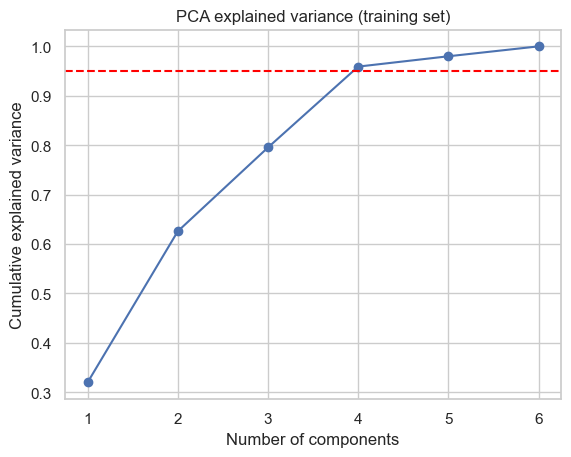

In [38]:
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_val_s = scaler.transform(x_val)

pca_full = PCA(random_state=RANDOM_STATE).fit(x_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
print("Explained variance ratio:", np.round(pca_full.explained_variance_ratio_, 3))
print("Cumulative variance:     ", np.round(cum, 3))

plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(PCA_VARIANCE, color="red", ls="--")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (training set)")
plt.show()


In [39]:
pca = PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE)
x_train_pca = pca.fit_transform(x_train_s)
x_val_pca = pca.transform(x_val_s)
print("Components kept:", pca.n_components_)


Components kept: 4


In [40]:
pca_rows = []
for model_name, model in selection_models.items():
    fitted = clone(model)
    fitted.fit(x_train_pca, y_train)
    predictions = fitted.predict(x_val_pca)
    report = classification_report(
        y_val, predictions, output_dict=True, zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()
    pca_rows.append({
        "Feature selection": "PCA",
        "Features": f"{pca.n_components_} components",
        "Model": model_name,
        "Validation accuracy": report["accuracy"],
        "Validation balanced accuracy": balanced_accuracy_score(y_val, predictions),
        "Validation failure precision": report["1"]["precision"],
        "Validation failure recall": report["1"]["recall"],
        "Validation failure F1": report["1"]["f1-score"],
        "Validation missed failures": fn,
        "Validation false alarms": fp,
    })

pca_results = pd.DataFrame(pca_rows)
print("PCA evaluation:")
display(pca_results.sort_values(PRIMARY_SORT_METRICS, ascending=False))


PCA evaluation:


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
5,PCA,4 components,MLP,0.976000,0.675435,0.857143,0.352941,0.500000,33,3
4,PCA,4 components,Gradient Boosting,0.973333,0.683514,0.703704,0.372549,0.487179,32,8
3,PCA,4 components,Random Forest,0.970000,0.643953,0.625000,0.294118,0.400000,36,9
2,PCA,4 components,Decision Tree,0.962667,0.668534,0.439024,0.352941,0.391304,33,23
0,PCA,4 components,SVC,0.878000,0.861182,0.197248,0.843137,0.319703,8,175
1,PCA,4 components,Logistic Regression,0.702667,0.751512,0.085954,0.803922,0.155303,10,436


 ## 14. Validation Comparison and Candidate Screening



 We now combine all validation results from every feature-selection method × model combination.

 - **Why we do this:** Screening lets us quickly compare all combinations using default hyperparameters on the Validation set ("practice exam").

 - The Test set ("final exam") remains completely hidden.

In [41]:
result_tables = {
    "No feature selection": baseline_results,
    "ANOVA": anova_results,
    "Pearson correlation": correlation_results,
    "Adapted Lasso": lasso_results,
    "Forward selection": forward_results,
    "Backward selection": backward_results,
    "RFE": rfe_results,
    "PCA": pca_results,
}

all_comparison_results = pd.concat(
    list(result_tables.values()),
    ignore_index=True,
)

selection_order = list(result_tables)
all_comparison_results["Feature selection"] = pd.Categorical(
    all_comparison_results["Feature selection"],
    categories=selection_order,
    ordered=True,
)

grouped_ranking = (
    all_comparison_results.sort_values(
        ["Feature selection"] + PRIMARY_SORT_METRICS + ["Model"],
        ascending=[True, False, False, False, False, True],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

print("Validation ranking within each feature-selection method:")
display(grouped_ranking)

best_per_selection = (
    grouped_ranking
    .groupby("Feature selection", observed=True, sort=False)
    .head(1)
    .sort_values(
        PRIMARY_SORT_METRICS + ["Model"],
        ascending=[False, False, False, False, True],
        kind="mergesort",
    )
    .reset_index(drop=True)
)

print("Best validation model from each feature-selection method:")
display(best_per_selection)


Validation ranking within each feature-selection method:


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.986000,0.841412,0.875000,0.686275,0.769231,16,5
1,No feature selection,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.984667,0.812345,0.888889,0.627451,0.735632,19,4
2,No feature selection,"Type, Air temperature [K], Process temperature...",Random Forest,0.984667,0.783969,0.966667,0.568627,0.716049,22,1
3,No feature selection,"Type, Air temperature [K], Process temperature...",Decision Tree,0.972667,0.777757,0.604167,0.568627,0.585859,22,19
4,No feature selection,"Type, Air temperature [K], Process temperature...",SVC,0.924667,0.904254,0.296053,0.882353,0.443350,6,107
5,No feature selection,"Type, Air temperature [K], Process temperature...",Logistic Regression,0.830000,0.826879,0.145833,0.823529,0.247788,9,246
6,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
7,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Gradient Boosting,0.977333,0.723420,0.793103,0.450980,0.575000,28,6
8,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",Random Forest,0.972667,0.654792,0.727273,0.313725,0.438356,35,6
9,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",SVC,0.918000,0.919722,0.283133,0.921569,0.433180,4,119


Best validation model from each feature-selection method:


,Feature selection,Features,Model,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.986000,0.841412,0.875000,0.686275,0.769231,16,5
1,RFE,"Air temperature [K], Process temperature [K], ...",MLP,0.981333,0.820079,0.767442,0.647059,0.702128,18,10
2,ANOVA,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
3,Pearson correlation,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
4,Adapted Lasso,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
5,Forward selection,"Air temperature [K], Rotational speed [rpm], T...",MLP,0.980667,0.791357,0.789474,0.588235,0.674157,21,8
6,Backward selection,"Air temperature [K], Process temperature [K], ...",MLP,0.979333,0.762290,0.794118,0.529412,0.635294,24,7
7,PCA,4 components,MLP,0.976000,0.675435,0.857143,0.352941,0.500000,33,3


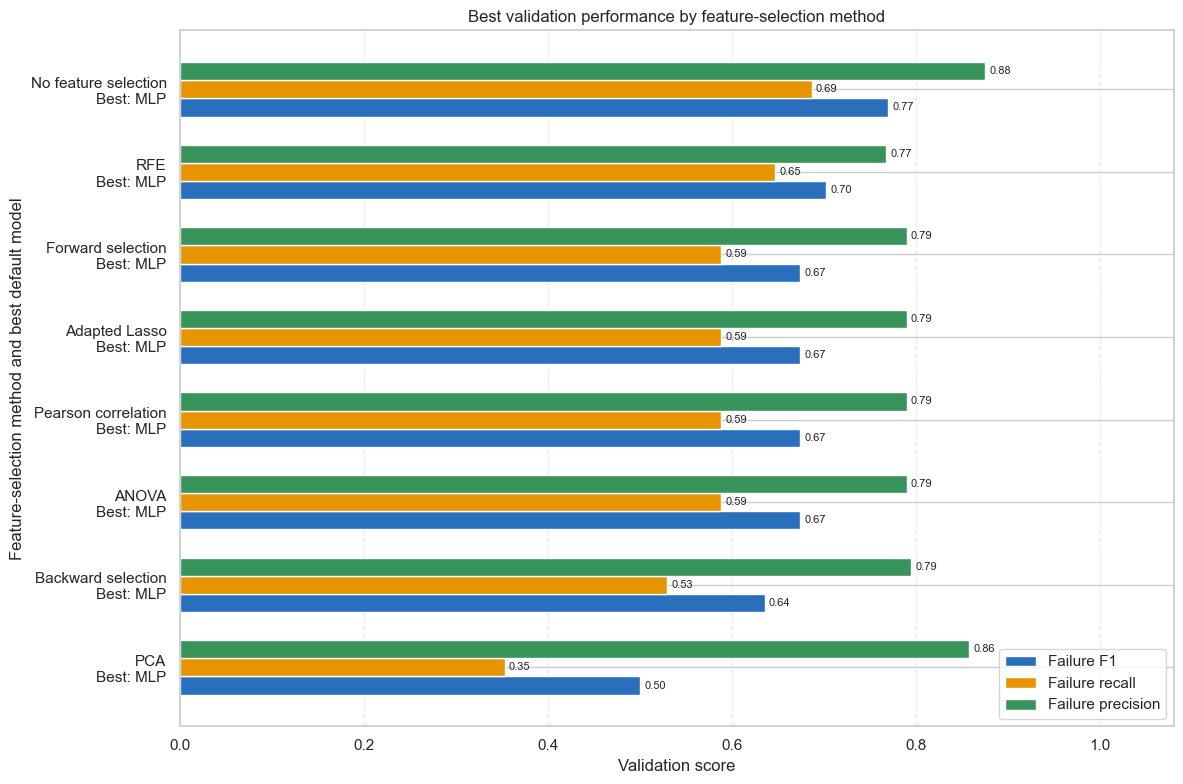

In [42]:
# Compare the best default-model result for each feature-selection method.
# These are validation-screening results; the held-out test set is not used here.
plot_results = best_per_selection.sort_values(
    "Validation failure F1", ascending=True
).reset_index(drop=True)

selection_labels = [
    f"{method}\nBest: {model}"
    for method, model in zip(
        plot_results["Feature selection"].astype(str),
        plot_results["Model"],
    )
]
metric_columns = [
    "Validation failure F1",
    "Validation failure recall",
    "Validation failure precision",
]
metric_labels = ["Failure F1", "Failure recall", "Failure precision"]
bar_colors = ["#2a6fbb", "#e69500", "#39945b"]
positions = np.arange(len(plot_results))
bar_height = 0.22

fig, ax = plt.subplots(figsize=(12, 8))
for offset, column, label, color in zip(
    [-bar_height, 0, bar_height], metric_columns, metric_labels, bar_colors
):
    values = plot_results[column].to_numpy()
    bars = ax.barh(
        positions + offset,
        values,
        height=bar_height,
        label=label,
        color=color,
    )
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)

ax.set_yticks(positions)
ax.set_yticklabels(selection_labels)
ax.set_xlim(0, 1.08)
ax.set_xlabel("Validation score")
ax.set_ylabel("Feature-selection method and best default model")
ax.set_title("Best validation performance by feature-selection method")
ax.xaxis.grid(True, linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Interpreting the feature-selection comparison

Each row shows the best default model found for one feature-selection method during validation screening. The bars compare positive-class failure F1, recall, and precision; F1 is the primary ranking metric, while recall and precision help show the balance between catching failures and raising false alarms. The winning model is included in each label because the best classifier can differ between selection methods.

This is an initial validation comparison, not the final tuned-model result. The finalists are tuned using cross-validation on the training data and then compared on validation data. The held-out test set is not used in this graph or to choose a feature-selection method.

### 14.1 Selecting the Top Three Finalists (Deduplicating Identical Sensor Subsets)

When selecting the Top 3 candidates from the screening table to advance to hyperparameter fine-tuning, we must handle a common issue in small-sensor datasets: **different feature-selection algorithms often pick the exact same subset of sensors** (for example, ANOVA may return `Air temp, Process temp, RPM, Torque` in column order, while Pearson correlation returns the exact same four sensors sorted by correlation strength: `Torque, RPM, Air temp, Process temp`).

If we only deduplicate by method name (`Feature selection`), the same model architecture trained on the exact same sensor columns would occupy multiple finalist slots as identical clones. To make finalist selection fair and meaningful, we standardize the feature names alphabetically (`Canonical features`) and apply the following rules:

1. **Merge Identical Clones (Same Model + Same Sensor Subset):** If two or more feature-selection methods select the exact same sensors for the same model, they are merged into a single entry (e.g., `ANOVA / Pearson correlation`) so we never waste time fine-tuning identical clones.
2. **Allow Different Models on the Same Sensor Subset:** Different model families (e.g., `Gradient Boosting` and `Random Forest`) using the same feature subset (such as `No feature selection`) are kept as separate candidates.
3. **Configurable Architecture Diversity (`UNIQUE_FINALIST_MODELS` in Section 7):**
   - When `UNIQUE_FINALIST_MODELS = False`, the **same model family** can appear more than once in the Top 3 if it performs strongly on **genuinely different sensor subsets** (e.g., `Random Forest` with all 6 sensors vs. `Random Forest` with 4 sensors).
   - When `UNIQUE_FINALIST_MODELS = True`, the Top 3 finalists are forced to be **three distinct model architectures**, each paired with its best-performing feature subset.

In [43]:
# 1. Create a canonical (alphabetically sorted) feature string so that
#    identical sensor subsets in different column orders are recognized as the same set.
all_comparison_results["Canonical features"] = all_comparison_results["Features"].apply(
    lambda s: s if "components" in str(s) else ", ".join(sorted([f.strip() for f in str(s).split(",")]))
)

# 2. Merge rows that have the exact same (Model + Canonical features)
unique_combinations = (
    all_comparison_results
    .sort_values(
        PRIMARY_SORT_METRICS + ["Feature selection", "Model"],
        ascending=[False, False, False, False, True, True],
        kind="mergesort",
    )
    .groupby(["Model", "Canonical features"], as_index=False, sort=False)
    .agg({
        # Combine selector names that picked the exact same subset (e.g., "ANOVA / Pearson correlation")
        "Feature selection": lambda s: " / ".join(dict.fromkeys(s.astype(str))),
        "Features": "first",
        "Validation accuracy": "first",
        "Validation balanced accuracy": "first",
        "Validation failure precision": "first",
        "Validation failure recall": "first",
        "Validation failure F1": "first",
        "Validation missed failures": "first",
        "Validation false alarms": "first",
    })
)

# 3. Select the Top 3 finalists based on the Master Config setting
dedup_cols = ["Model"] if UNIQUE_FINALIST_MODELS else ["Model", "Canonical features"]

top_three_candidates = (
    unique_combinations
    .sort_values(
        PRIMARY_SORT_METRICS + ["Model"],
        ascending=[False, False, False, False, True],
        kind="mergesort",
    )
    .drop_duplicates(subset=dedup_cols, keep="first")
    .head(3)
    .reset_index(drop=True)
    .drop(columns=["Canonical features"])
)

print(f"Top 3 candidates advancing to Hyperparameter Fine-Tuning (UNIQUE_FINALIST_MODELS={UNIQUE_FINALIST_MODELS}):")
display(top_three_candidates)

Top 3 candidates advancing to Hyperparameter Fine-Tuning (UNIQUE_FINALIST_MODELS=False):


,Model,Feature selection,Features,Validation accuracy,Validation balanced accuracy,Validation failure precision,Validation failure recall,Validation failure F1,Validation missed failures,Validation false alarms
0,MLP,No feature selection,"Type, Air temperature [K], Process temperature...",0.986000,0.841412,0.875000,0.686275,0.769231,16,5
1,Gradient Boosting,No feature selection,"Type, Air temperature [K], Process temperature...",0.984667,0.812345,0.888889,0.627451,0.735632,19,4
2,Random Forest,No feature selection,"Type, Air temperature [K], Process temperature...",0.984667,0.783969,0.966667,0.568627,0.716049,22,1


## --- IGNORE ---
## 15. NEW Stacking Ensemble Experiment (Standalone Validation Check) BELOW AT 17

- **What:** We take the Top 3 distinct models from screening and combine them into a single `StackingClassifier` using Logistic Regression as the meta-model (`final_estimator`).
- **Why:** Stacking is the third ensemble paradigm in our syllabus (alongside Bagging and Boosting). We run this as a standalone validation experiment to see if combining the Top 3 models improves upon the #1 individual model. However, for simplicity and interpretability, only the Top 3 individual models advance to hyperparameter fine-tuning and final selection.

 ## 16. Fine-Tune the Top Three Finalists (5-Fold Cross-Validation)



 Screening evaluated models using default settings. Now we **fine-tune** the Top 3 finalists using 5-Fold Stratified Cross-Validation (`GridSearchCV`) on the Training set (`x_train`).

 - **Why this counts as fine-tuning:** Instead of retraining the same configuration, `GridSearchCV` systematically searches internal structural hyperparameters (such as SVM kernel type Linear/Poly/RBF, regularization $C$, tree depth, learning rate, and MLP hidden layer sizes) across 5 training/validation folds to find the optimal mathematical settings.



 | Split | Purpose |
 |---|---|
 | **Training (70%)** | Fit models and run 5-fold cross-validation hyperparameter tuning |
 | **Validation (15%)** | Screen combinations and choose the single best tuned winner |
 | **Test (15%)** | Untouched final exam — used once at the very end |

In [44]:
original_features = list(x_train.columns)

def make_tuning_model(model_name):
    """Return (model, parameter_grid) with syllabus-aligned hyperparameter grids."""
    if model_name == "SVC":
        model = make_pipeline(
            StandardScaler(),
            SVC(probability=True, random_state=RANDOM_STATE),
        )
        grid = [
            {
                "svc__kernel": ["linear"],
                "svc__C": [0.1, 1, 10],
                "svc__class_weight": [None, "balanced"],
                "svc__probability": [True],
            },
            {
                "svc__kernel": ["rbf"],
                "svc__C": [0.1, 1, 10],
                "svc__gamma": ["scale", "auto"],
                "svc__class_weight": [None, "balanced"],
                "svc__probability": [True],
            },
            {
                "svc__kernel": ["poly"],
                "svc__C": [0.1, 1, 10],
                "svc__degree": [2, 3],
                "svc__class_weight": [None, "balanced"],
                "svc__probability": [True],
            },
        ]
    elif model_name == "Logistic Regression":
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        )
        grid = [
            {
                "logisticregression__penalty": ["l1"],
                "logisticregression__solver": ["liblinear"],
                "logisticregression__C": [0.01, 0.1, 1, 10],
                "logisticregression__class_weight": [None, "balanced"],
            },
            {
                "logisticregression__penalty": ["l2"],
                "logisticregression__solver": ["lbfgs"],
                "logisticregression__C": [0.01, 0.1, 1, 10],
                "logisticregression__class_weight": [None, "balanced"],
            },
        ]
    elif model_name == "Decision Tree":
        model = DecisionTreeClassifier(random_state=RANDOM_STATE)
        grid = {
            "criterion": ["gini", "entropy"],
            "max_depth": [None, 5, 10],
            "min_samples_split": [2, 10],
            "class_weight": [None, "balanced"],
        }
    elif model_name == "Random Forest":
        model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
        grid = {
            "n_estimators": [100, 200],
            "max_depth": [None, 10],
            "min_samples_leaf": [1, 5],
            "class_weight": [None, "balanced"],
        }
    elif model_name == "Gradient Boosting":
        model = GradientBoostingClassifier(random_state=RANDOM_STATE)
        grid = {
            "n_estimators": [100, 200],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 5],
            "subsample": [0.8, 1.0],
        }
    elif model_name == "MLP":
        model = make_pipeline(
            StandardScaler(),
            MLPClassifier(max_iter=1000, random_state=RANDOM_STATE),
        )
        grid = {
            "mlpclassifier__hidden_layer_sizes": [
                (31,), (64,), (128,),
                (32, 16), (64, 16), (64, 32),
            ],
            "mlpclassifier__alpha": [0.0001, 0.001, 0.01],
        }
    else:
        raise ValueError(f"Unsupported model: {model_name}")
    return model, grid

def candidate_input_features(candidate):
    if candidate["Feature selection"] == "PCA":
        return original_features
    return [feature.strip() for feature in str(candidate["Features"]).split(",")]

def build_tuning_model(model_name, use_pca):
    model, parameter_grid = make_tuning_model(model_name)
    if not use_pca:
        return model, parameter_grid

    pca_model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=PCA_VARIANCE, random_state=RANDOM_STATE)),
        ("model", model),
    ])
    if isinstance(parameter_grid, list):
        pca_grid = [
            {f"model__{key}": value for key, value in grid.items()}
            for grid in parameter_grid
        ]
    else:
        pca_grid = {
            f"model__{key}": value for key, value in parameter_grid.items()
        }
    return pca_model, pca_grid

cv_strategy = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

tuned_models = []
for index, candidate in top_three_candidates.iterrows():
    input_features = candidate_input_features(candidate)
    model, parameter_grid = build_tuning_model(
        candidate["Model"],
        candidate["Feature selection"] == "PCA",
    )
    print(
        f"Tuning candidate {index + 1}/{len(top_three_candidates)}: "
        f"{candidate['Model']} ({candidate['Feature selection']})"
    )

    search = GridSearchCV(
        estimator=model,
        param_grid=parameter_grid,
        scoring={
            "f1": "f1",
            "recall": "recall",
            "precision": "precision",
            "balanced_accuracy": "balanced_accuracy",
        },
        refit="f1",
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=True,
    )
    search.fit(x_train[input_features], y_train)

    best_index = search.best_index_
    tuned_models.append({
        "Feature selection": candidate["Feature selection"],
        "Model": candidate["Model"],
        "Features": candidate["Features"],
        "Input features": input_features,
        "Search": search,
        "Best parameters": search.best_params_,
        "CV F1 mean": search.cv_results_["mean_test_f1"][best_index],
        "CV F1 std": search.cv_results_["std_test_f1"][best_index],
        "CV recall mean": search.cv_results_["mean_test_recall"][best_index],
        "CV precision mean": search.cv_results_["mean_test_precision"][best_index],
        "CV balanced accuracy mean": search.cv_results_["mean_test_balanced_accuracy"][best_index],
        "CV train F1 mean": search.cv_results_["mean_train_f1"][best_index],
        "Number of grid combinations": len(search.cv_results_["params"]),
    })

tuning_results = pd.DataFrame(tuned_models).drop(columns=["Search"]).sort_values(
    ["CV F1 mean", "CV recall mean", "CV precision mean", "Model"],
    ascending=[False, False, False, True],
    kind="mergesort",
).reset_index(drop=True)

print("Cross-validation tuning results on training data:")
display(tuning_results)


Tuning candidate 1/3: MLP (No feature selection)
Tuning candidate 2/3: Gradient Boosting (No feature selection)
Tuning candidate 3/3: Random Forest (No feature selection)
Cross-validation tuning results on training data:


,Feature selection,Model,Features,Input features,Best parameters,CV F1 mean,CV F1 std,CV recall mean,CV precision mean,CV balanced accuracy mean,CV train F1 mean,Number of grid combinations
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...","[Type, Air temperature [K], Process temperatur...","{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.735597,0.039728,0.692287,0.791109,0.842891,1.000000,16
1,No feature selection,Random Forest,"Type, Air temperature [K], Process temperature...","[Type, Air temperature [K], Process temperatur...","{'class_weight': None, 'max_depth': None, 'min...",0.695148,0.036931,0.578103,0.873527,0.787573,1.000000,16
2,No feature selection,MLP,"Type, Air temperature [K], Process temperature...","[Type, Air temperature [K], Process temperatur...","{'mlpclassifier__alpha': 0.01, 'mlpclassifier_...",0.694023,0.037135,0.632624,0.777869,0.812911,0.808927,18


In [45]:
def evaluate_on_split(model, metadata, features, X_split, y_split, prefix, display_features=None):
    """Evaluate one fitted model on a named data split."""
    predictions = model.predict(X_split[features])
    report = classification_report(
        y_split,
        predictions,
        output_dict=True,
        zero_division=0,
    )
    tn, fp, fn, tp = confusion_matrix(
        y_split,
        predictions,
        labels=[0, 1],
    ).ravel()
    return {
        "Feature selection": metadata["Feature selection"],
        "Model": metadata["Model"],
        "Features": (
            ", ".join(display_features)
            if isinstance(display_features, list)
            else str(display_features)
        )
        if display_features is not None
        else ", ".join(features),
        f"{prefix} F1": report["1"]["f1-score"],
        f"{prefix} recall": report["1"]["recall"],
        f"{prefix} precision": report["1"]["precision"],
        f"{prefix} balanced accuracy": balanced_accuracy_score(y_split, predictions),
        f"{prefix} missed failures": fn,
        f"{prefix} false alarms": fp,
        "Predictions": predictions,
    }

# Evaluate every tuned finalist on the validation split
validation_finalist_rows = []
for result in tuned_models:
    metadata = {
        "Feature selection": result["Feature selection"],
        "Model": result["Model"],
    }
    validation_finalist_rows.append(
        evaluate_on_split(
            result["Search"].best_estimator_,
            metadata,
            result["Input features"],
            x_val,
            y_val,
            "Validation",
            result["Features"],
        )
    )

validation_finalist_results = pd.DataFrame(
    validation_finalist_rows
).sort_values(
    ["Validation F1", "Validation recall", "Validation precision", "Model"],
    ascending=[False, False, False, True],
    kind="mergesort",
).reset_index(drop=True)

print("Tuned finalists compared on the Validation split:")
display(validation_finalist_results.drop(columns=["Predictions"]))


Tuned finalists compared on the Validation split:


,Feature selection,Model,Features,Validation F1,Validation recall,Validation precision,Validation balanced accuracy,Validation missed failures,Validation false alarms
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...",0.786517,0.686275,0.921053,0.842102,16,3
1,No feature selection,Random Forest,"Type, Air temperature [K], Process temperature...",0.777778,0.686275,0.897436,0.841757,16,4
2,No feature selection,MLP,"Type, Air temperature [K], Process temperature...",0.757895,0.705882,0.818182,0.850181,15,8


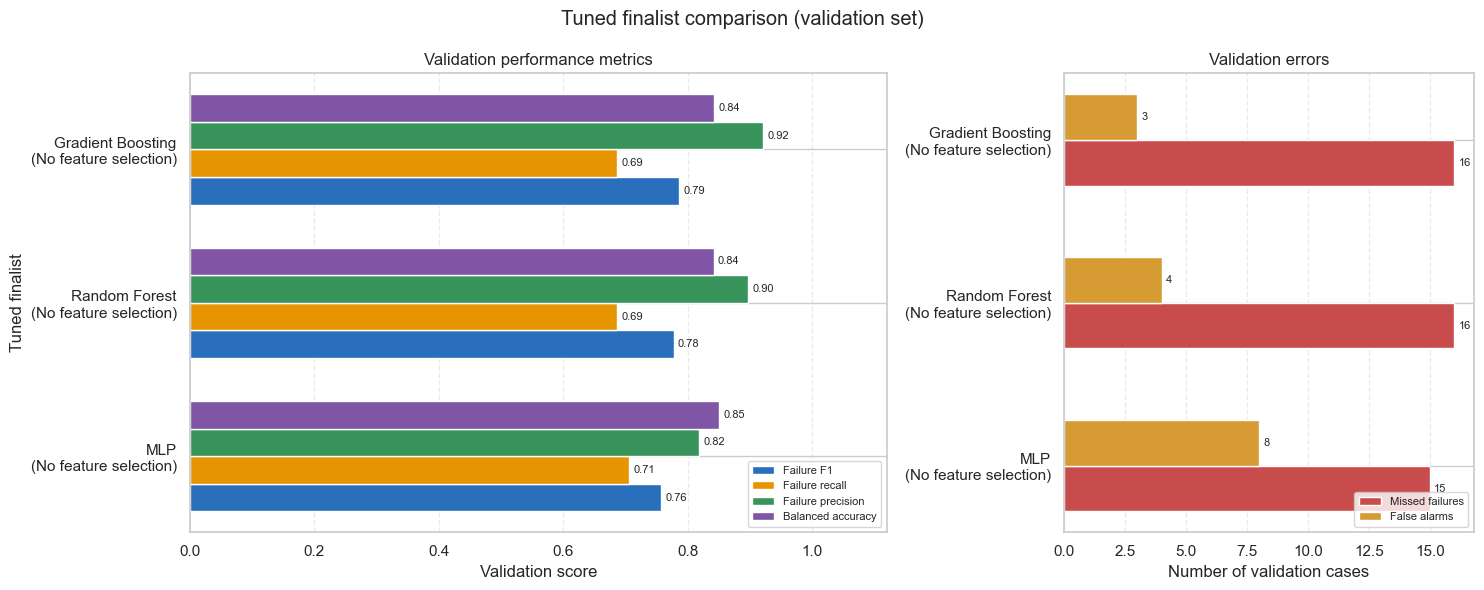

In [46]:
# Compare tuned finalist models using validation metrics only.
# The held-out test set remains reserved for the final evaluation.
finalist_plot = validation_finalist_results.sort_values(
    "Validation F1", ascending=True
).reset_index(drop=True)
model_labels = [
    f"{model}\n({method})"
    for model, method in zip(
        finalist_plot["Model"],
        finalist_plot["Feature selection"].astype(str),
    )
]
metric_columns = [
    "Validation F1",
    "Validation recall",
    "Validation precision",
    "Validation balanced accuracy",
]
metric_labels = ["Failure F1", "Failure recall", "Failure precision", "Balanced accuracy"]
metric_colors = ["#2a6fbb", "#e69500", "#39945b", "#8055a5"]
positions = np.arange(len(finalist_plot))
bar_height = 0.18

fig, (ax_metrics, ax_errors) = plt.subplots(
    1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.7, 1]}
)
for offset, column, label, color in zip(
    [-1.5 * bar_height, -0.5 * bar_height, 0.5 * bar_height, 1.5 * bar_height],
    metric_columns,
    metric_labels,
    metric_colors,
):
    bars = ax_metrics.barh(
        positions + offset,
        finalist_plot[column],
        height=bar_height,
        label=label,
        color=color,
    )
    ax_metrics.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)

ax_metrics.set_yticks(positions)
ax_metrics.set_yticklabels(model_labels)
ax_metrics.set_xlim(0, 1.12)
ax_metrics.set_xlabel("Validation score")
ax_metrics.set_ylabel("Tuned finalist")
ax_metrics.set_title("Validation performance metrics")
ax_metrics.xaxis.grid(True, linestyle="--", alpha=0.4)
ax_metrics.set_axisbelow(True)
ax_metrics.legend(loc="lower right", fontsize=8)

error_columns = ["Validation missed failures", "Validation false alarms"]
error_labels = ["Missed failures", "False alarms"]
error_colors = ["#c94c4c", "#d69b32"]
error_height = 0.28
for offset, column, label, color in zip(
    [-error_height / 2, error_height / 2],
    error_columns,
    error_labels,
    error_colors,
):
    bars = ax_errors.barh(
        positions + offset,
        finalist_plot[column],
        height=error_height,
        label=label,
        color=color,
    )
    ax_errors.bar_label(bars, padding=3, fontsize=8)

ax_errors.set_yticks(positions)
ax_errors.set_yticklabels(model_labels)
ax_errors.set_xlabel("Number of validation cases")
ax_errors.set_title("Validation errors")
ax_errors.xaxis.grid(True, linestyle="--", alpha=0.4)
ax_errors.set_axisbelow(True)
ax_errors.legend(loc="lower right", fontsize=8)
fig.suptitle("Tuned finalist comparison (validation set)")
plt.tight_layout()
plt.show()

### Interpreting the tuned finalist comparison

The left panel compares each tuned finalist on validation failure F1, recall, precision, and balanced accuracy. Failure F1 summarizes the precision?recall balance for the positive (failure) class; recall reflects the proportion of failures detected, while precision reflects the proportion of failure alerts that were correct. Balanced accuracy gives equal weight to the recall of both classes, which is useful when failures are uncommon.

The right panel shows the corresponding validation counts of missed failures and false alarms. These counts make the practical trade-off more concrete: fewer missed failures may come with more false alarms. Read the panels together with the underlying results table, and interpret small score differences cautiously because they come from one validation split.

These results compare tuned finalists on validation data. The test set is not shown and must not be used to select the winner; it remains reserved for the final, one-time evaluation.

 ### 16.1 Select the Final Tuned Winner



 We select and freeze the winning model, feature set, and hyperparameters using **Validation metrics only**. The test set is still untouched.

In [47]:
final_winner = validation_finalist_results.iloc[0]
final_result = next(
    result for result in tuned_models
    if result["Model"] == final_winner["Model"]
    and result["Feature selection"] == final_winner["Feature selection"]
)
final_metadata = {
    "Feature selection": final_result["Feature selection"],
    "Model": final_result["Model"],
}

print(
    f"Selected winner: {final_winner['Model']} "
    f"({final_winner['Feature selection']})"
)
print("Selected hyperparameters:", final_result["Best parameters"])


Selected winner: Gradient Boosting (No feature selection)
Selected hyperparameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1.0}


,Feature,Mean F1 decrease,Importance standard deviation
4,Torque [Nm],0.4468,0.0191
1,Air temperature [K],0.3487,0.0358
3,Rotational speed [rpm],0.3045,0.0241
2,Process temperature [K],0.2120,0.0287
5,Tool wear [min],0.1177,0.0228
0,Type,0.0306,0.0171


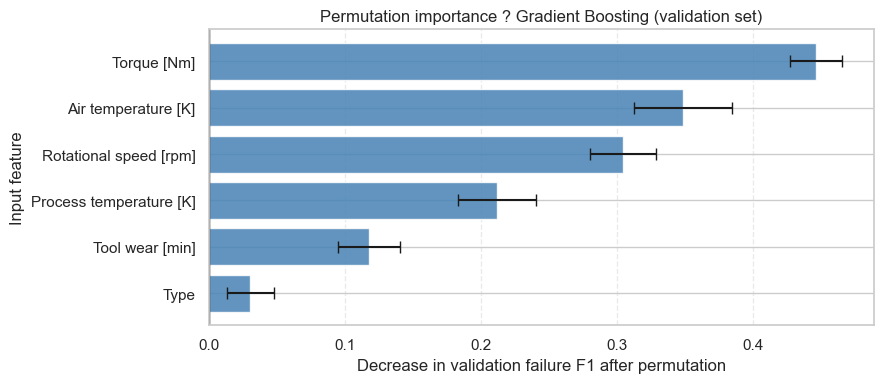

In [48]:
from sklearn.inspection import permutation_importance

# Estimate feature importance for the selected tuned model using validation data.
# This is descriptive only; do not use it to revise the already-selected model.
importance_result = permutation_importance(
    final_result["Search"].best_estimator_,
    x_val[final_result["Input features"]],
    y_val,
    scoring="f1",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance_table = pd.DataFrame({
    "Feature": final_result["Input features"],
    "Mean F1 decrease": importance_result.importances_mean,
    "Importance standard deviation": importance_result.importances_std,
}).sort_values("Mean F1 decrease", ascending=True)

display(importance_table.sort_values("Mean F1 decrease", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(9, max(4, 0.55 * len(importance_table))))
ax.barh(
    importance_table["Feature"],
    importance_table["Mean F1 decrease"],
    xerr=importance_table["Importance standard deviation"],
    color="steelblue",
    alpha=0.85,
    capsize=4,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Decrease in validation failure F1 after permutation")
ax.set_ylabel("Input feature")
ax.set_title(f"Permutation importance ? {final_result['Model']} (validation set)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Interpreting winning-model feature importance

This chart uses **permutation importance**: one input feature is shuffled at a time in the validation data, and the tuned winning model's failure F1 is recalculated. A larger positive mean decrease means the model relied more on that feature for its validation predictions. The error bars show the standard deviation across repeated shuffles; values near zero, or negative values, suggest little stable benefit under this procedure.

This describes how this particular fitted model behaves; it does not show that a feature causes failure. Correlated sensors can share or mask importance, and the validation split was also used to choose the winner, so these estimates are descriptive rather than an independent evaluation. Do not use this chart to change the selected model or report it as test-set importance. The test set remains reserved for the final performance evaluation.

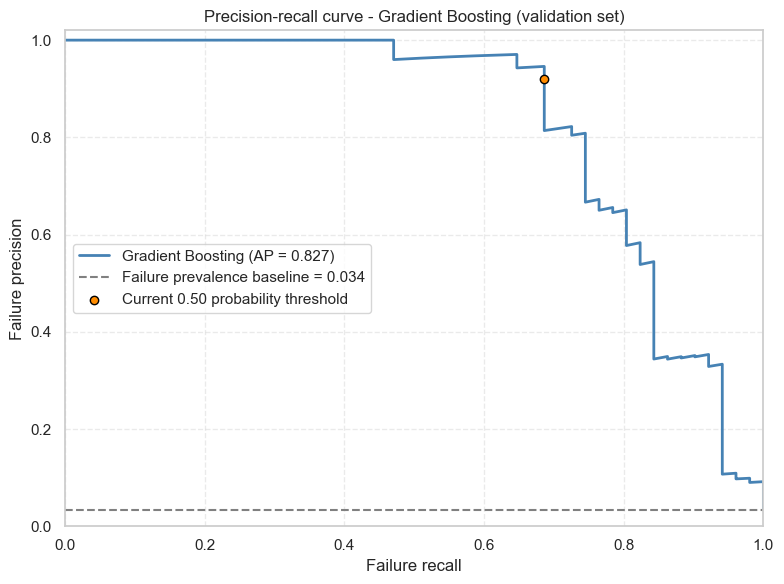

Validation average precision: 0.8270
At probability threshold 0.50: precision=0.9211, recall=0.6863


In [49]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_recall_fscore_support,
)

# Plot the selected tuned model's precision-recall trade-off on validation data.
winning_model = final_result["Search"].best_estimator_
validation_features = x_val[final_result["Input features"]]
positive_class_index = list(winning_model.classes_).index(1)
validation_failure_scores = winning_model.predict_proba(validation_features)[:, positive_class_index]
precision_values, recall_values, _ = precision_recall_curve(
    y_val,
    validation_failure_scores,
    pos_label=1,
)
average_precision = average_precision_score(y_val, validation_failure_scores)
validation_prevalence = y_val.mean()

# Mark the model's default probability threshold without tuning it on the test set.
default_predictions = (validation_failure_scores >= 0.5).astype(int)
default_precision, default_recall, _, _ = precision_recall_fscore_support(
    y_val,
    default_predictions,
    average="binary",
    pos_label=1,
    zero_division=0,
)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(
    recall_values,
    precision_values,
    color="steelblue",
    linewidth=2,
    label=f"{final_result['Model']} (AP = {average_precision:.3f})",
)
ax.axhline(
    validation_prevalence,
    color="gray",
    linestyle="--",
    label=f"Failure prevalence baseline = {validation_prevalence:.3f}",
)
ax.scatter(
    [default_recall],
    [default_precision],
    color="darkorange",
    edgecolor="black",
    zorder=3,
    label="Current 0.50 probability threshold",
)
ax.set(
    xlim=(0, 1),
    ylim=(0, 1.02),
    xlabel="Failure recall",
    ylabel="Failure precision",
    title=f"Precision-recall curve - {final_result['Model']} (validation set)",
)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

print(f"Validation average precision: {average_precision:.4f}")
print(f"At probability threshold 0.50: precision={default_precision:.4f}, recall={default_recall:.4f}")

### Interpreting the precision-recall curve

The curve shows the trade-off between failure **precision** (how many failure alerts are correct) and failure **recall** (how many actual failures are detected) as the classification threshold changes. The horizontal dashed line is the failure prevalence in the validation set, a useful no-skill precision reference for this imbalanced target. Average precision (AP) summarizes precision across recall levels; higher values indicate a stronger precision-recall profile, but AP is not the same as the F1 score at one threshold.

The orange point marks the current 0.50 probability threshold used by the model's predictions. Moving to a different threshold may increase recall while reducing precision, or vice versa. This plot is based on validation data: if you choose a new operating threshold, justify and freeze it using validation data only, then evaluate that fixed choice once on the held-out test set. Do not select a threshold by looking at test results.

 ### 16.2 Refit on the 85% Development Data



 Now that the winning architecture, feature subset, and hyperparameters are frozen, we combine the Training (70%) and Validation (15%) splits into an 85% development set and refit the winner once so it learns from all available non-test data.

In [50]:
x_development = pd.concat([x_train, x_val], axis=0)
y_development = pd.concat([y_train, y_val], axis=0)

final_estimator = clone(final_result["Search"].best_estimator_)
final_estimator.fit(
    x_development[final_result["Input features"]],
    y_development,
)

print(f"Final model refit on {len(x_development)} development samples.")


Final model refit on 8500 development samples.


## 17. Final Test Evaluation (Tuned Single Winner vs. Stacking Ensemble)

This is the **only** section that touches `y_test`. Both approaches were selected using Validation performance only and refitted on the **85% Development Set** (`x_development`, `8,500` rows):
1. **Selected Single-Model Winner:** The #1 fine-tuned individual classifier from Section 16.
2. **Selected Ensemble Benchmark (`Stacking Top 3`):** Combines our 3 fine-tuned finalist architectures with a Logistic Regression meta-model.

We evaluate both on the unseen 15% Test Set (`1,500` rows) to compare single-model deployment against multi-model stacking on unseen data.

Final Unseen Test Set Evaluation (Single Winner vs. Stacking Ensemble):


,Feature selection,Model,Features,Test F1,Test recall,Test precision,Test balanced accuracy,Test missed failures,Test false alarms
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...",0.813187,0.725490,0.925,0.861710,14,3
1,No feature selection,Stacking (Tuned Top 3),"Type, Air temperature [K], Process temperature...",0.791209,0.705882,0.900,0.851561,15,4


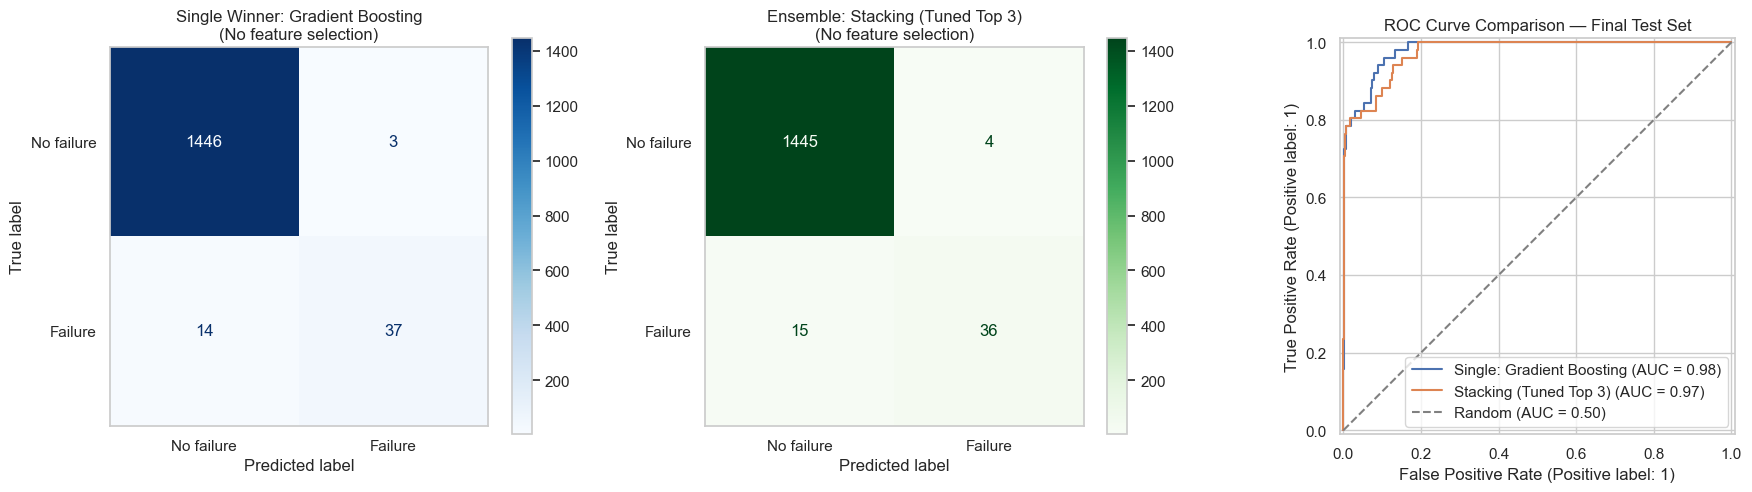

In [51]:
# 1. Refit the Stacking Ensemble on the 85% Development Set using the 3 tuned finalists
tuned_base_learners = [
    (res["Model"].lower().replace(" ", "_"), clone(res["Search"].best_estimator_))
    for res in tuned_models
]

final_stacking_estimator = StackingClassifier(
    estimators=tuned_base_learners,
    final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    cv=CV_FOLDS,
    n_jobs=-1,
)
final_stacking_estimator.fit(
    x_development[final_result["Input features"]],
    y_development,
)

# 2. Evaluate the #1 Tuned Single Winner on the unseen Test Set
final_test_result = evaluate_on_split(
    final_estimator,
    final_metadata,
    final_result["Input features"],
    x_test,
    y_test,
    "Test",
    final_result["Features"],
)

# 3. Evaluate the Stacking Ensemble on the unseen Test Set
stacking_test_metadata = {
    "Feature selection": final_result["Feature selection"],
    "Model": "Stacking (Tuned Top 3)",
}
stacking_test_result = evaluate_on_split(
    final_stacking_estimator,
    stacking_test_metadata,
    final_result["Input features"],
    x_test,
    y_test,
    "Test",
    final_result["Features"],
)

stacking_row = {
    "Feature selection": stacking_test_metadata["Feature selection"],
    "Model": stacking_test_metadata["Model"],
    "Features": final_result["Features"],
    "Test F1": stacking_test_result["Test F1"],
    "Test recall": stacking_test_result["Test recall"],
    "Test precision": stacking_test_result["Test precision"],
    "Test balanced accuracy": stacking_test_result["Test balanced accuracy"],
    "Test missed failures": stacking_test_result["Test missed failures"],
    "Test false alarms": stacking_test_result["Test false alarms"],
    "Predictions": stacking_test_result["Predictions"],
}

comparison_df = pd.DataFrame([stacking_row])

# 4. Display side-by-side Final Test Table
final_test_comparison_df = pd.DataFrame([
    {k: v for k, v in final_test_result.items() if k != "Predictions"},
    {k: v for k, v in stacking_test_result.items() if k != "Predictions"},
])
print("Final Unseen Test Set Evaluation (Single Winner vs. Stacking Ensemble):")
display(final_test_comparison_df)

# 5. Plot Confusion Matrices + Combined ROC Curve (1x3 grid)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Single Winner Confusion Matrix
cm_single = confusion_matrix(y_test, final_test_result["Predictions"], labels=[0, 1])
ConfusionMatrixDisplay(cm_single, display_labels=["No failure", "Failure"]).plot(
    cmap="Blues", values_format="d", ax=axes[0]
)
axes[0].set_title(f"Single Winner: {final_winner['Model']}\n({final_winner['Feature selection']})")
axes[0].grid(False)

# Plot 2: Stacking Ensemble Confusion Matrix
cm_stack = confusion_matrix(y_test, stacking_test_result["Predictions"], labels=[0, 1])
ConfusionMatrixDisplay(cm_stack, display_labels=["No failure", "Failure"]).plot(
    cmap="Greens", values_format="d", ax=axes[1]
)
axes[1].set_title(f"Ensemble: Stacking (Tuned Top 3)\n({final_winner['Feature selection']})")
axes[1].grid(False)

# Plot 3: Combined ROC Curves on the same axes
RocCurveDisplay.from_estimator(
    final_estimator,
    x_test[final_result["Input features"]],
    y_test,
    name=f"Single: {final_winner['Model']}",
    ax=axes[2],
)
RocCurveDisplay.from_estimator(
    final_stacking_estimator,
    x_test[final_result["Input features"]],
    y_test,
    name="Stacking (Tuned Top 3)",
    ax=axes[2],
)
axes[2].plot([0, 1], [0, 1], ls="--", color="grey", label="Random (AUC = 0.50)")
axes[2].set_title("ROC Curve Comparison — Final Test Set")
axes[2].legend(loc="lower right")

plt.tight_layout()
plt.show()

Final unseen test result:


,Feature selection,Model,Features,Test F1,Test recall,Test precision,Test balanced accuracy,Test missed failures,Test false alarms
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...",0.813187,0.72549,0.925,0.86171,14,3


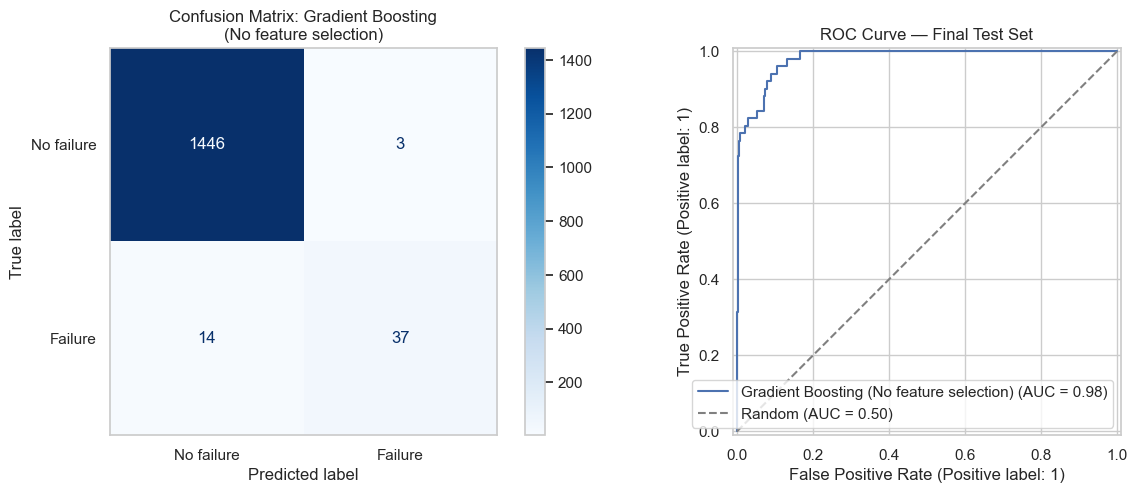

In [52]:
# 
# 
#  OLD VERSION: Only evaluate the #1 Tuned Single Winner on the unseen Test Set
# 
# 
final_test_result = evaluate_on_split(
    final_estimator,
    final_metadata,
    final_result["Input features"],
    x_test,
    y_test,
    "Test",
    final_result["Features"],
)

print("Final unseen test result:")
display(
    pd.DataFrame([{
        key: value
        for key, value in final_test_result.items()
        if key != "Predictions"
    }])
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1) Confusion Matrix
cm = confusion_matrix(y_test, final_test_result["Predictions"], labels=[0, 1])
ConfusionMatrixDisplay(
    cm,
    display_labels=["No failure", "Failure"],
).plot(cmap="Blues", values_format="d", ax=axes[0])
axes[0].set_title(
    f"Confusion Matrix: {final_winner['Model']}\n({final_winner['Feature selection']})"
)
axes[0].grid(False)

# 2) ROC Curve & AUC
RocCurveDisplay.from_estimator(
    final_estimator,
    x_test[final_result["Input features"]],
    y_test,
    name=f"{final_winner['Model']} ({final_winner['Feature selection']})",
    ax=axes[1],
)
axes[1].plot([0, 1], [0, 1], ls="--", color="grey", label="Random (AUC = 0.50)")
axes[1].set_title("ROC Curve — Final Test Set")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


 ## 18. Term Project Conclusion and Recommendations



 This project demonstrates a complete, leak-free supervised machine learning workflow:



 1. **Explore & Preprocess:** Inspected the AI4I 2020 dataset, visualized physical failure boundaries, encoded `Type`, and removed target-leaking failure mode columns.

 2. **Strict Data Partitioning:** Split the data into 70% Training, 15% Validation, and 15% Test sets.

 3. **Feature Selection & Dimensionality Reduction:** Compared Filter (ANOVA, Pearson), Embedded (Adapted Lasso, Ridge, Elastic Net), Wrapper (RFE, Forward/Backward SFS), and PCA methods fitted strictly on the training set.

 4. **Candidate Screening & Stacking:** Screened 6 model families across all feature sets on the Validation split, selected the Top 3 distinct architectures, and tested a dynamic Stacking Ensemble.

 5. **Hyperparameter Fine-Tuning:** Tuned the Top 3 finalists using 5-Fold Stratified Cross-Validation on the training split.

 6. **Final Unseen Evaluation:** Refit the validation winner on the 85% development set and evaluated once on the 15% test set using F1, Recall, Precision, Balanced Accuracy, Confusion Matrix, and ROC-AUC.

## 19. Experiment Run Logger & Summary Exporter

Run the cell below every time you test a new configuration in **Section 7 (Master Experiment Configuration)**. It automatically:
1. **Appends** your current configuration, selected feature sets, Top 3 screening finalists, Stacking comparison, tuned winner, and final Test metrics to a cumulative text log (`experiment_runs_log.txt`) so you never lose previous runs.
2. **Generates** a clean, readable Markdown report (`latest_experiment_report.md`) and a multi-page **PDF summary (`experiment_summary.pdf`)** with comparison tables and charts so your team can easily compare approaches and pick the best one for your class presentation.

In [53]:
from datetime import datetime
from matplotlib.backends.backend_pdf import PdfPages

timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# 1. Build a clean text/markdown summary of the current configuration & results
run_summary_lines = [
    "=" * 80,
    f"EXPERIMENT RUN LOG — {timestamp}",
    "=" * 80,
    "",
    "1. MASTER CONFIGURATION SETTINGS:",
    f"   - RANDOM_STATE           : {RANDOM_STATE}",
    f"   - NUMBER_OF_FEATURES     : {NUMBER_OF_FEATURES}",
    f"   - RFE_SELECTOR_MODEL     : {RFE_SELECTOR_MODEL}",
    f"   - SFS_SELECTOR_MODEL     : {SFS_SELECTOR_MODEL}",
    f"   - PCA_VARIANCE           : {PCA_VARIANCE} ({pca.n_components_} components kept)",
    f"   - CV_FOLDS               : {CV_FOLDS}",
    f"   - UNIQUE_FINALIST_MODELS : {UNIQUE_FINALIST_MODELS}",
    "",
    "2. FEATURES SELECTED BY EACH METHOD:",
    f"   - Baseline (All 6)       : {', '.join(x_train.columns)}",
    f"   - ANOVA                  : {', '.join(anova_features)}",
    f"   - Pearson Correlation    : {', '.join(correlation_features)}",
    f"   - Adapted Lasso (L1)     : {', '.join(lasso_features)}",
    f"   - RFE ({RFE_SELECTOR_MODEL}) : {', '.join(rfe_features)}",
    f"   - Forward SFS ({SFS_SELECTOR_MODEL}) : {', '.join(forward_features)}",
    f"   - Backward SFS ({SFS_SELECTOR_MODEL}): {', '.join(backward_features)}",
    f"   - PCA ({PCA_VARIANCE*100:.0f}% var)        : {pca.n_components_} orthogonal components",
    "",
    "3. BEST MODEL PER FEATURE-SELECTION METHOD (VALIDATION SCREENING):",
    best_per_selection[[
        "Feature selection", "Model", "Validation failure F1",
        "Validation failure recall", "Validation failure precision",
        "Validation missed failures", "Validation false alarms"
    ]].to_string(index=False),
    "",
    "4. TOP 3 FINALISTS AFTER 5-FOLD CV HYPERPARAMETER TUNING (VALIDATION):",
    validation_finalist_results.drop(columns=["Predictions"])[[
        "Feature selection", "Model", "Validation F1",
        "Validation recall", "Validation precision",
        "Validation missed failures", "Validation false alarms"
    ]].to_string(index=False),
    "",
    "5. STACKING ENSEMBLE Of Top 3 Fine Tuned Models(VALIDATION):",
        comparison_df[[
            "Feature selection", "Model", "Test F1",
            "Test recall", "Test precision",
            "Test missed failures", "Test false alarms"
        ]].to_string(index=False),
        "",
    "6. SELECTED WINNER & TUNED HYPERPARAMETERS:",
    f"   - Winning Model          : {final_winner['Model']}",
    f"   - Winning Feature Method : {final_winner['Feature selection']} ({final_result['Features']})",
    f"   - Best Hyperparameters   : {final_result['Best parameters']}",
    "",
    "7. FINAL UNSEEN TEST SET PERFORMANCE (SINGLE WINNER VS. STACKING):",
    final_test_comparison_df.to_string(index=False),
    "=" * 80,
    "\n"
    f"   - Test Failure F1        : {final_test_result['Test F1']:.4f}",
    f"   - Test Failure Recall    : {final_test_result['Test recall']:.4f}",
    f"   - Test Failure Precision : {final_test_result['Test precision']:.4f}",
    f"   - Test Balanced Accuracy : {final_test_result['Test balanced accuracy']:.4f}",
    f"   - Test Missed Failures   : {final_test_result['Test missed failures']}",
    f"   - Test False Alarms      : {final_test_result['Test false alarms']}",
    "=" * 80,
    "\n"
]

report_text = "\n".join(run_summary_lines)

# 2. Append to cumulative text log (keeps history of all configurations you test!)
log_txt_path = "./Report/experiment_runs_log.txt"
with open(log_txt_path, "a", encoding="utf-8") as f:
    f.write(report_text)

# 3. Save a clean single-run Markdown report for easy reading in VS Code
md_path = "./Report/latest_experiment_report.md"
with open(md_path, "w", encoding="utf-8") as f:
    f.write(f"# Experiment Summary Report ({timestamp})\n\n```text\n{report_text}\n```\n")

print(f"Saved cumulative log to : {log_txt_path}")
print(f"Saved Markdown report to: {md_path}")
# print(f"Saved PDF report to     : {pdf_path}\n")
print(report_text)

Saved cumulative log to : ./Report/experiment_runs_log.txt
Saved Markdown report to: ./Report/latest_experiment_report.md
EXPERIMENT RUN LOG — 2026-10-31 12:16:13

1. MASTER CONFIGURATION SETTINGS:
   - RANDOM_STATE           : 55
   - NUMBER_OF_FEATURES     : 4
   - RFE_SELECTOR_MODEL     : Logistic Regression
   - SFS_SELECTOR_MODEL     : Decision Tree
   - PCA_VARIANCE           : 0.95 (4 components kept)
   - CV_FOLDS               : 5
   - UNIQUE_FINALIST_MODELS : False

2. FEATURES SELECTED BY EACH METHOD:
   - Baseline (All 6)       : Type, Air temperature [K], Process temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min]
   - ANOVA                  : Air temperature [K], Rotational speed [rpm], Torque [Nm], Tool wear [min]
   - Pearson Correlation    : Torque [Nm], Tool wear [min], Air temperature [K], Rotational speed [rpm]
   - Adapted Lasso (L1)     : Torque [Nm], Rotational speed [rpm], Air temperature [K], Tool wear [min]
   - RFE (Logistic Regression) : Ai

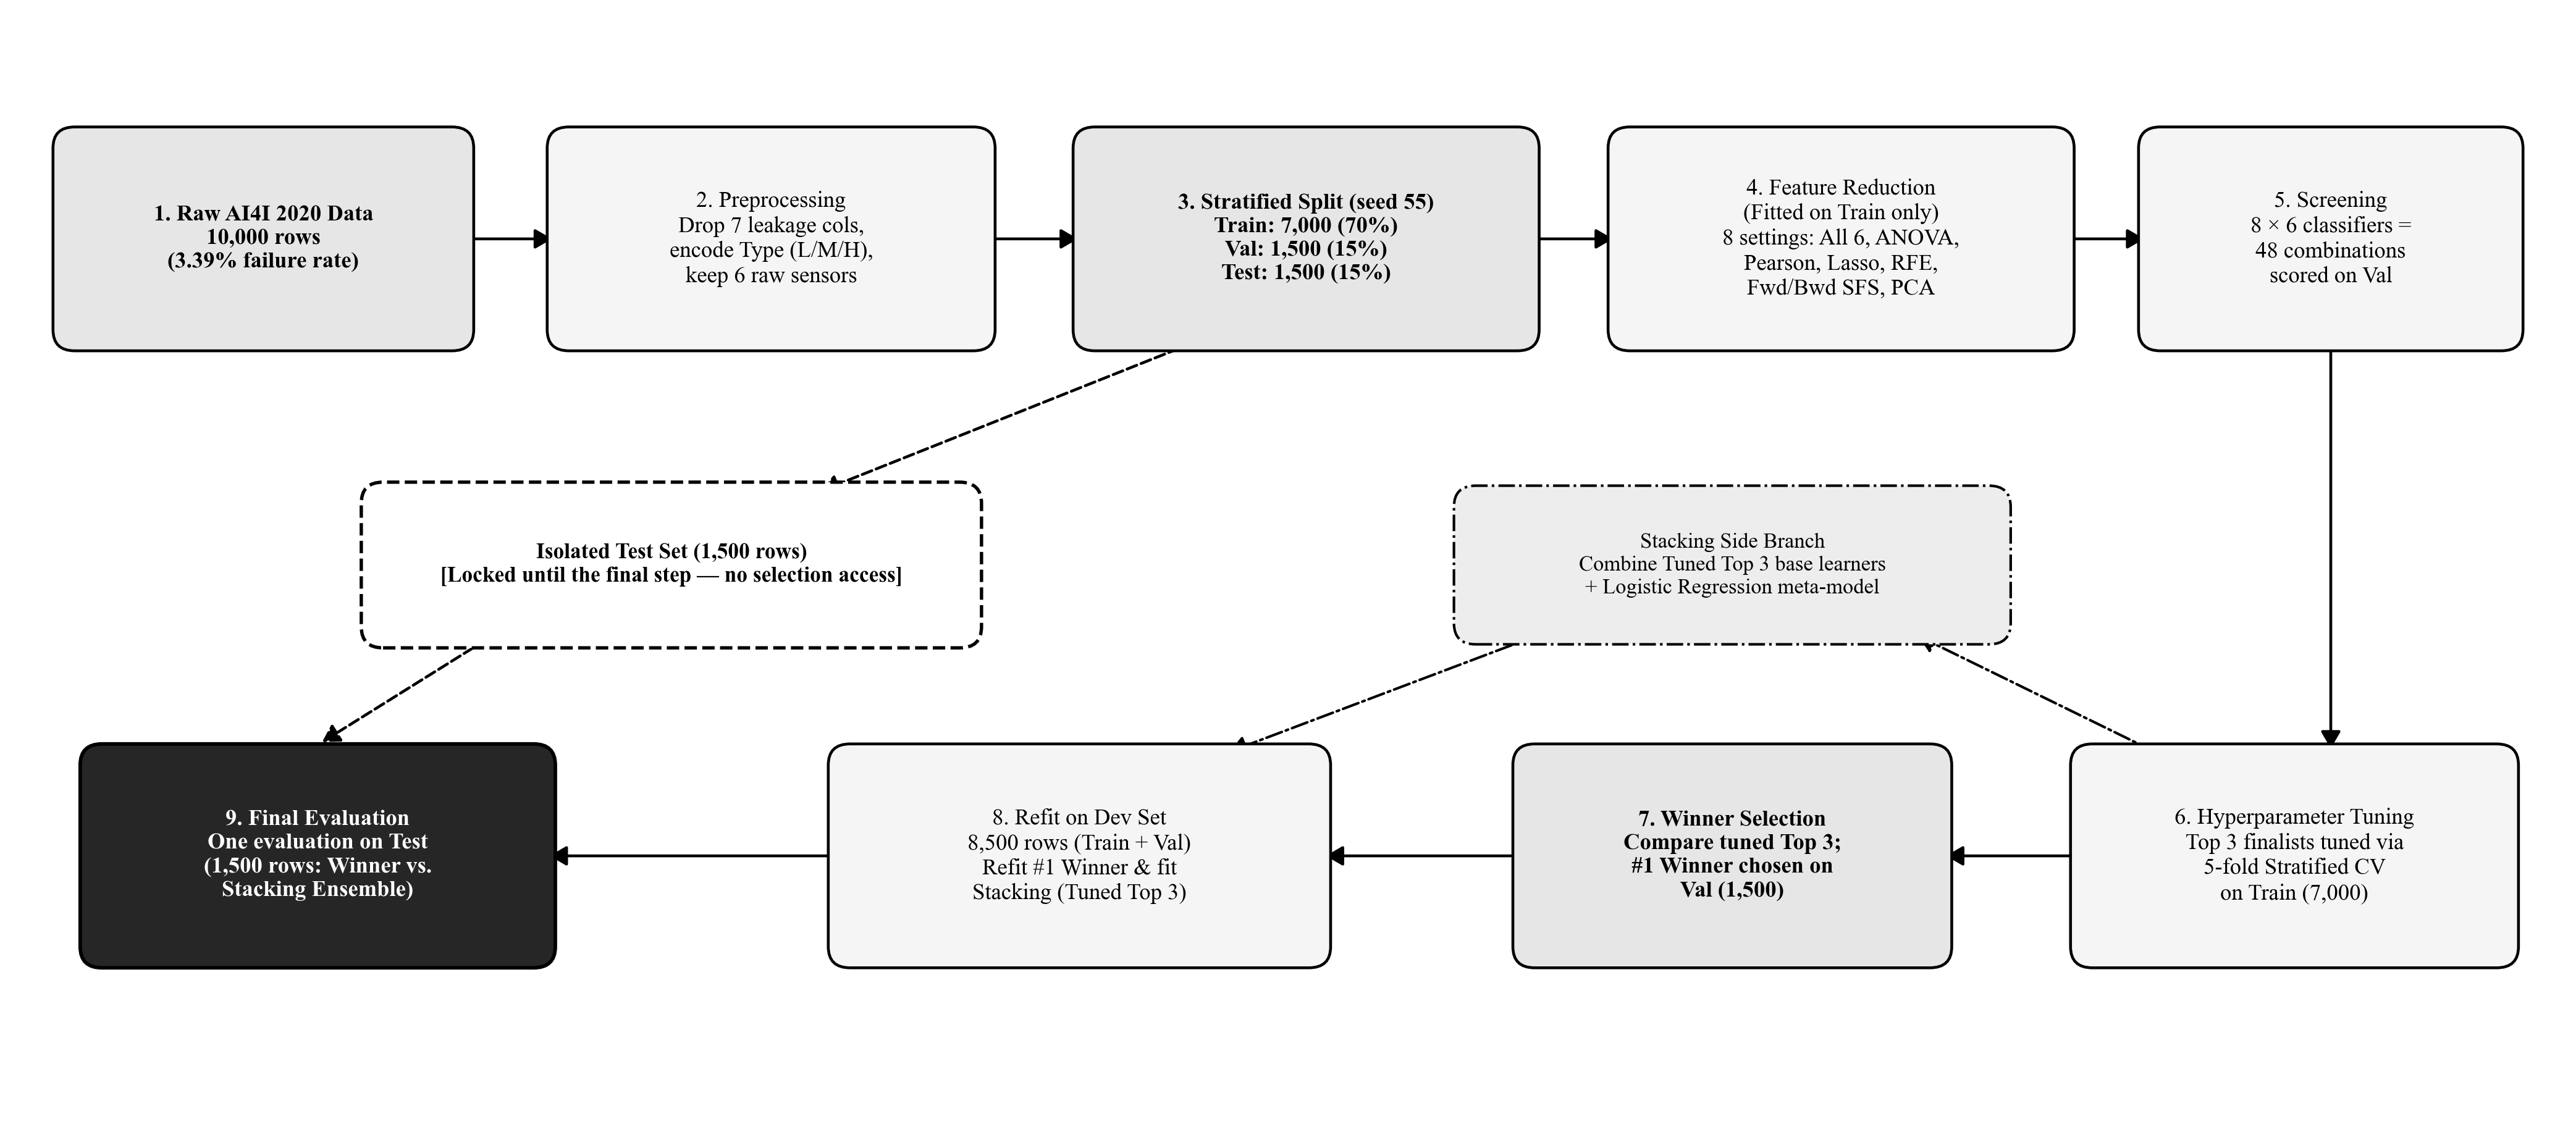

Saved Fig. 1 -> ./Report/figures\fig1_workflow.png


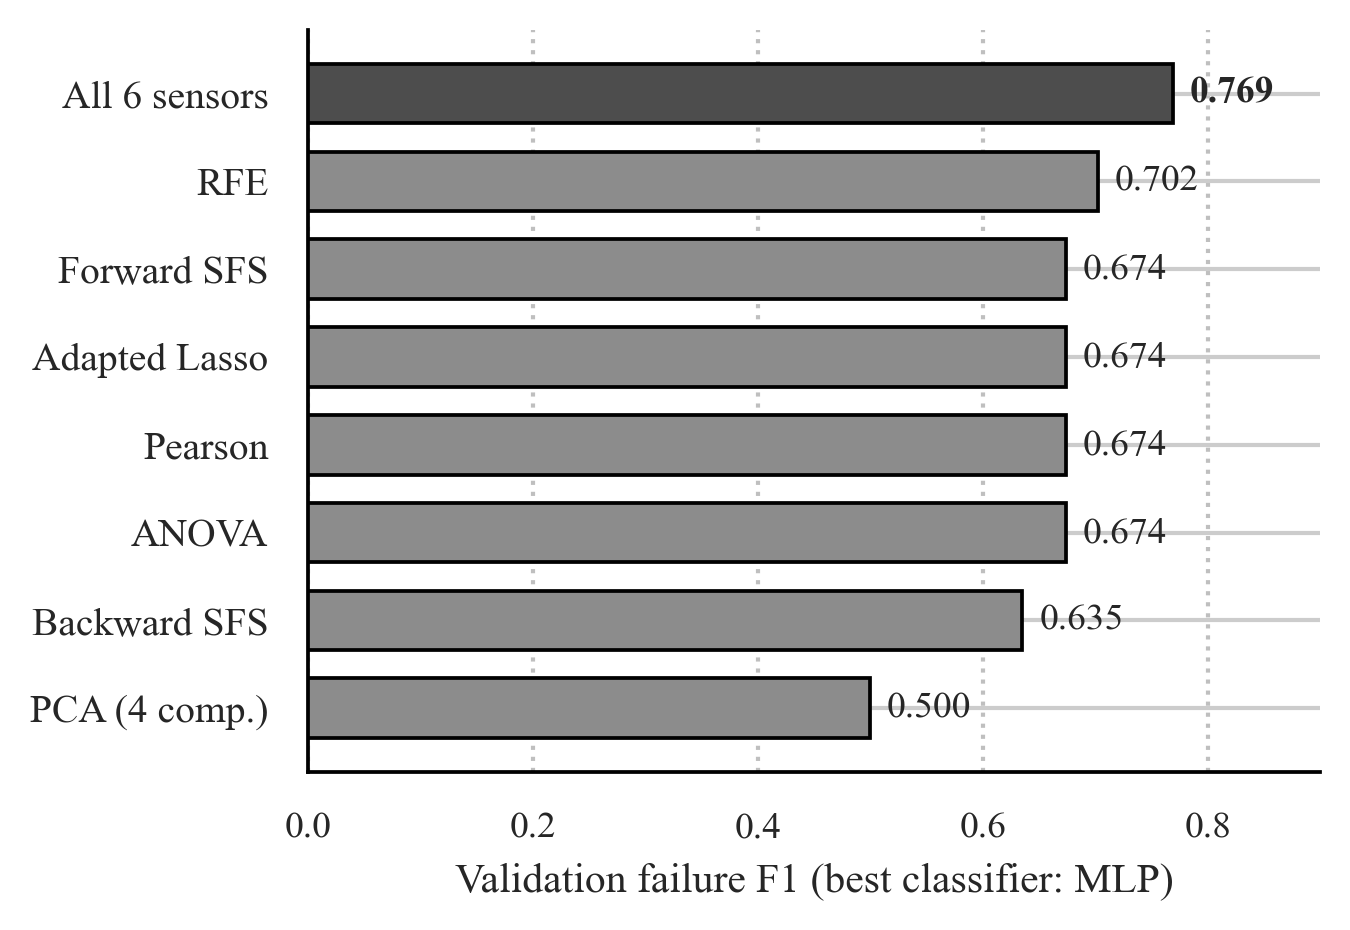

Saved Fig. 2 -> ./Report/figures\fig2_validation_f1.png


C:\Users\ROG\AppData\Local\Temp\ipykernel_23656\2270337434.py:296: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


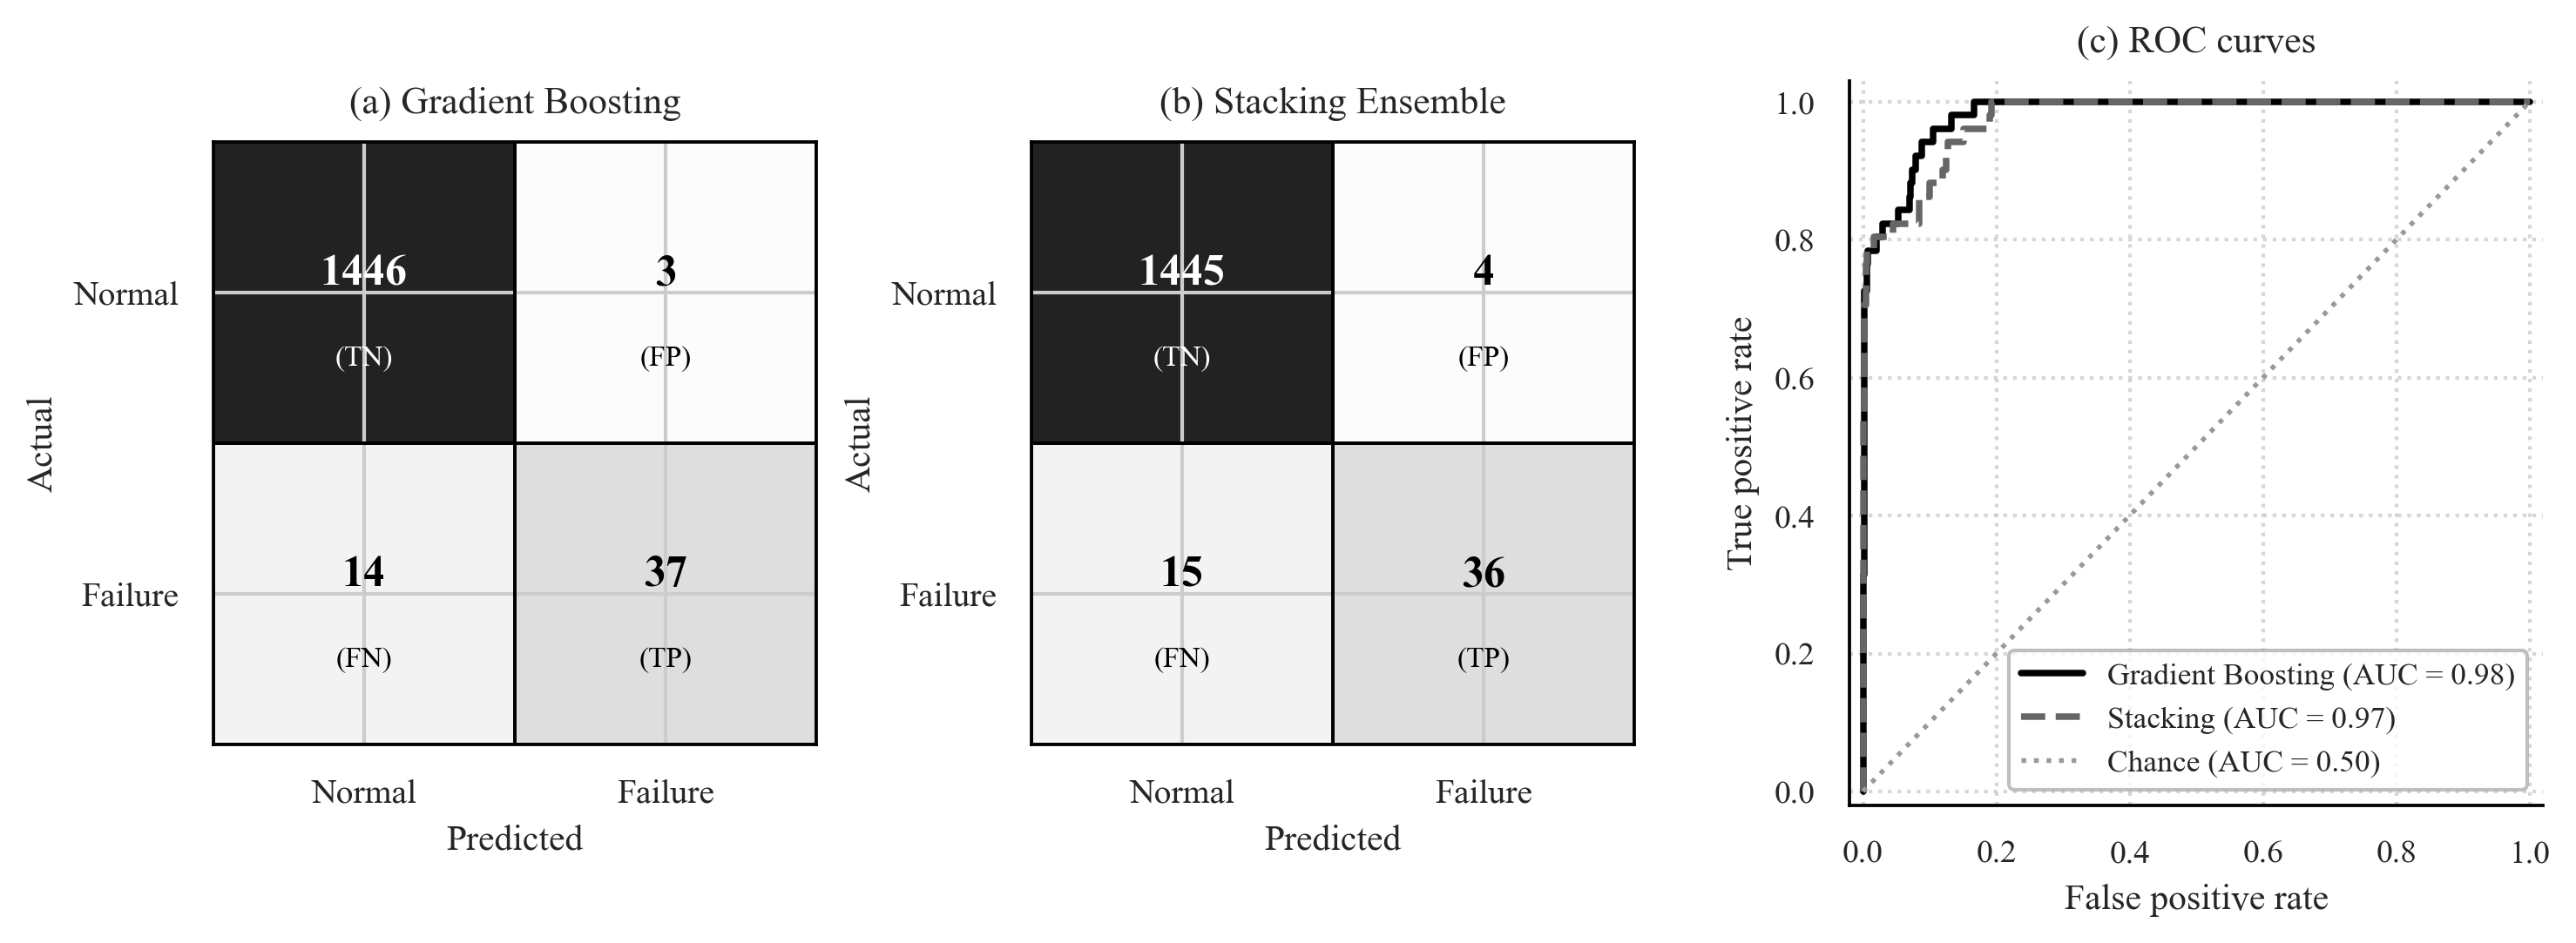

Saved Fig. 3 -> ./Report/figures\fig3_test_results.png


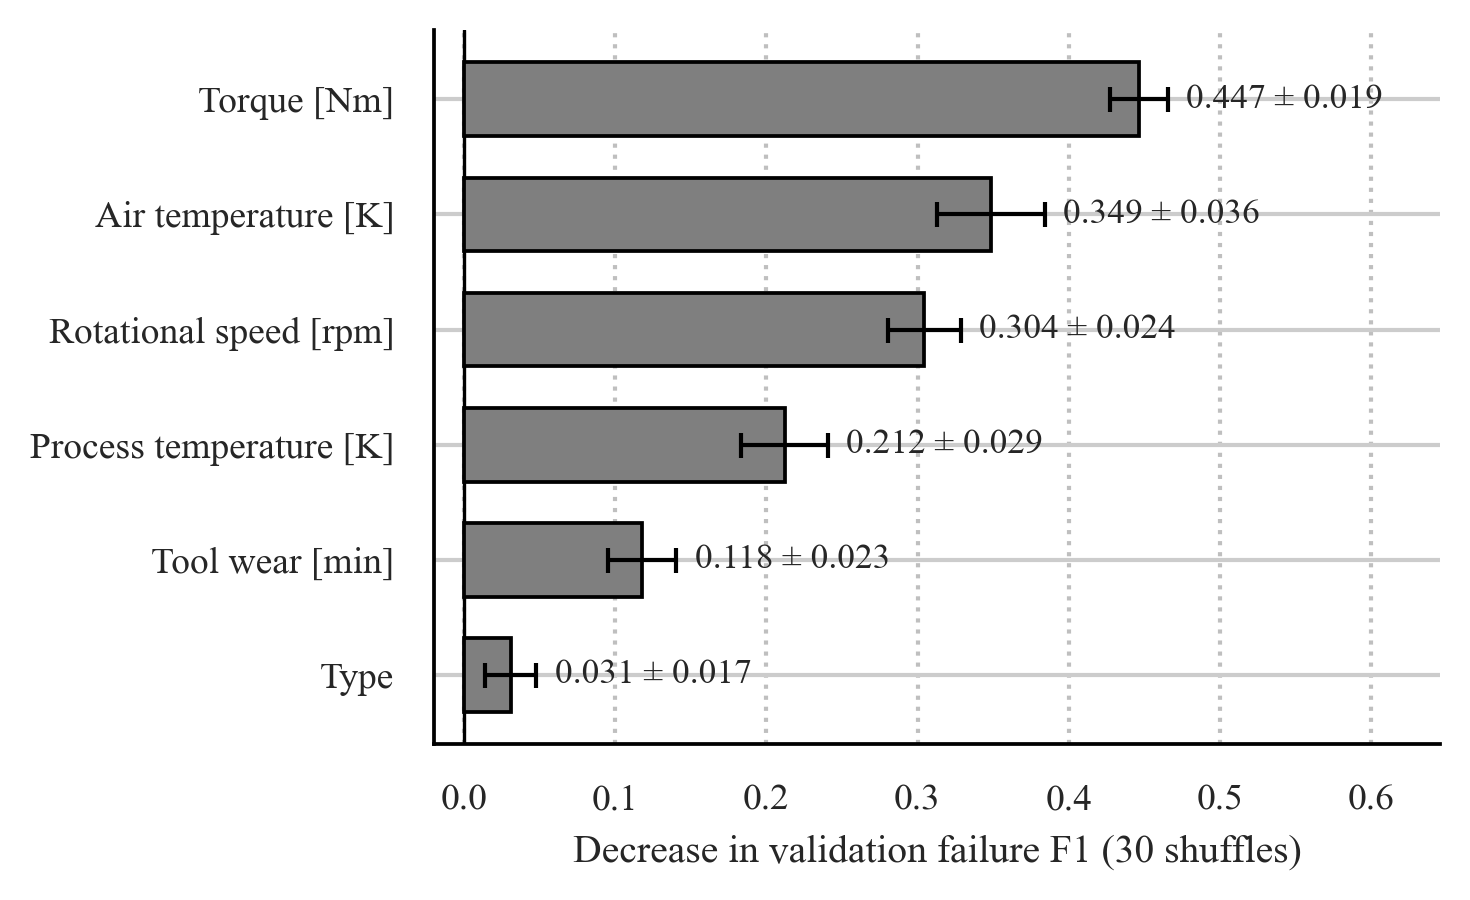

Saved Optional Fig. 4 -> ./Report/figures\fig4_permutation_importance.png

[CHECK] EXACT NUMBERS FOR PAPER CAPTIONS & OPTIONAL FIG. 4
Test ROC-AUC (Gradient Boosting) : 0.9815 (2-dec: 0.98)
Test ROC-AUC (Stacking Ensemble) : 0.9749 (2-dec: 0.97)

Optional Fig. 4 — Permutation Importance on Validation Split (30 repeats):
                Feature Mean_F1_Decrease Std_F1_Decrease
            Torque [Nm]           0.4468          0.0191
    Air temperature [K]           0.3487          0.0358
 Rotational speed [rpm]           0.3045          0.0241
Process temperature [K]           0.2120          0.0287
        Tool wear [min]           0.1177          0.0228
                   Type           0.0306          0.0171


In [54]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.inspection import permutation_importance

# Create output directory
FIG_DIR = "./Report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Global IEEE / Academic Grayscale Style
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "Computer Modern Roman"],
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10.5,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.edgecolor": "black",
    "axes.linewidth": 0.9,
})

# ==============================================================================
# FIG. 1: WORKFLOW FLOWCHART (Two-Column Width, Grayscale, No Test Leakage)
# ==============================================================================
fig1, ax1 = plt.subplots(figsize=(14, 6.2))
ax1.set_xlim(0, 14)
ax1.set_ylim(0, 6.2)
ax1.axis("off")

def draw_box(ax, x, y, w, h, text, facecolor="#F2F2F2", edgecolor="black", lw=1.1, ls="-", fontsize=8.8, weight="normal", textcolor="black"):
    box = FancyBboxPatch(
        (x - w / 2, y - h / 2), w, h,
        boxstyle="round,pad=0.06,rounding_size=0.12",
        facecolor=facecolor, edgecolor=edgecolor, linewidth=lw, linestyle=ls, zorder=3
    )
    ax.add_patch(box)
    ax.text(
        x, y, text, ha="center", va="center",
        fontsize=fontsize, fontweight=weight, color=textcolor,
        linespacing=1.25, zorder=4
    )

def draw_arrow(ax, x1, y1, x2, y2, ls="-", lw=1.1, color="black", rad=0.0):
    arrow = FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle="-|>,head_length=5.5,head_width=3.2",
        connectionstyle=f"arc3,rad={rad}",
        linestyle=ls, linewidth=lw, color=color, zorder=2
    )
    ax.add_patch(arrow)

# --- Top Row: Steps 1 to 5 (Left to Right) ---
y_top = 4.95
draw_box(ax1, 1.35, y_top, 2.2, 1.15, "1. Raw AI4I 2020 Data\n10,000 rows\n(3.39% failure rate)",
        facecolor="#E6E6E6", weight="bold")

draw_box(ax1, 4.15, y_top, 2.35, 1.15,
        "2. Preprocessing\nDrop 7 leakage cols,\nencode Type (L/M/H),\nkeep 6 raw sensors",
        facecolor="#F5F5F5")

draw_box(ax1, 7.10, y_top, 2.45, 1.15,
        "3. Stratified Split (seed 2077)\nTrain: 7,000 (70%)\nVal: 1,500 (15%)\nTest: 1,500 (15%)",
        facecolor="#E6E6E6", weight="bold")
draw_box(ax1, 10.05, y_top, 2.45, 1.15,
        "4. Feature Reduction\n(Fitted on Train only)\n9 settings: All 6, ANOVA,\nPearson, Lasso, RFE,\nFwd/Bwd SFS, PCA",
        facecolor="#F5F5F5")

draw_box(ax1, 12.75, y_top, 2.0, 1.15,
        "5. Screening\n9 × 6 classifiers =\n54 combinations\nscored on Val",
        facecolor="#F5F5F5")

draw_box(ax1, 10.05, 3.85, 2.45, 0.50,
        "Drop Type only",
        facecolor="#FFFFFF", edgecolor="black", lw=1.0, ls="--", fontsize=8.5, weight="bold")

# Arrows along Top Row
draw_arrow(ax1, 2.45, y_top, 2.97, y_top)
draw_arrow(ax1, 5.33, y_top, 5.87, y_top)
draw_arrow(ax1, 8.33, y_top, 8.82, y_top)
draw_arrow(ax1, 11.28, y_top, 11.75, y_top)

# --- Middle Isolated Box: Locked Test Set (from Step 3 straight to Step 9) ---
draw_box(ax1, 3.60, 3.10, 3.30, 0.82,
        "Isolated Test Set (1,500 rows)\n[Locked until the final step — no selection access]",
        facecolor="#FFFFFF", edgecolor="black", lw=1.3, ls="--", fontsize=8.5, weight="bold")

# Arrow from Step 3 down to Locked Test Set, then down to Step 9
draw_arrow(ax1, 6.50, y_top - 0.58, 4.40, 3.51, ls="--", lw=1.1)
draw_arrow(ax1, 2.60, 2.69, 1.65, 2.08, ls="--", lw=1.1)

# --- Bottom Row: Steps 6 to 9 (Right to Left) ---
y_bot = 1.45
draw_box(ax1, 12.55, y_bot, 2.35, 1.15,
        "6. Hyperparameter Tuning\nTop 3 finalists tuned via\n5-fold Stratified CV\non Train (7,000)",
        facecolor="#F5F5F5")

draw_box(ax1, 9.45, y_bot, 2.30, 1.15,
        "7. Winner Selection\nCompare tuned Top 3;\n#1 Winner chosen on\nVal (1,500)",
        facecolor="#E6E6E6", weight="bold")

draw_box(ax1, 5.85, y_bot, 2.65, 1.15,
        "8. Refit on Dev Set\n8,500 rows (Train + Val)\nRefit #1 Winner & fit\nStacking: GB + GB + RF",
        facecolor="#F5F5F5")

draw_box(ax1, 1.65, y_bot, 2.50, 1.15,
        "9. Final Evaluation\nOne evaluation on Test\n(1,500 rows: Winner vs.\nStacking Ensemble)",
        facecolor="#262626", edgecolor="black", lw=1.4, weight="bold", textcolor="white")

# Arrow from Step 5 down to Step 6
draw_arrow(ax1, 12.75, y_top - 0.58, 12.75, y_bot + 0.58)
# Arrows along Bottom Row (Right to Left: 6 -> 7 -> 8 -> 9)
draw_arrow(ax1, 11.37, y_bot, 10.60, y_bot)
draw_arrow(ax1, 8.30, y_bot, 7.18, y_bot)
draw_arrow(ax1, 4.52, y_bot, 2.90, y_bot)

# --- Side Branch: Stacking Ensemble (from Step 6 into Step 8) ---
draw_box(ax1, 9.45, 2.75, 2.95, 0.72,
        "Stacking: GB + GB + RF\n+ Logistic Regression meta-model",
        facecolor="#EDEDED", edgecolor="black", lw=1.0, ls="-.", fontsize=8.3)

# Arrow from Step 6 to Stacking Side Branch, then into Step 8
draw_arrow(ax1, 11.80, y_bot + 0.58, 10.45, 2.75, ls="-.", lw=1.0)
draw_arrow(ax1, 8.40, 2.75, 6.65, y_bot + 0.58, ls="-.", lw=1.0)

plt.tight_layout()
fig1_path = os.path.join(FIG_DIR, "fig1_workflow.png")
fig1.savefig(fig1_path, dpi=300, bbox_inches="tight", facecolor="white")
fig1.savefig(os.path.join(FIG_DIR, "fig1_workflow.pdf"), bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved Fig. 1 -> {fig1_path}")


# ==============================================================================
# FIG. 2: HORIZONTAL BAR CHART — BEST VALIDATION F1 PER STRATEGY (Single Column)
# ==============================================================================
label_map_fig2 = {
    "No feature selection": "All 6 sensors",
    "RFE": "RFE",
    "Forward selection": "Forward SFS",
    "Adapted Lasso": "Adapted Lasso",
    "Pearson correlation": "Pearson",
    "ANOVA": "ANOVA",
    "Backward selection": "Backward SFS",
    "PCA": f"PCA ({pca.n_components_} comp.)",
}

# Explicit bottom-to-top order matching your paper figure
desired_order_bottom_to_top = [
    f"PCA ({pca.n_components_} comp.)",
    "Backward SFS",
    "ANOVA",
    "Pearson",
    "Adapted Lasso",
    "Forward SFS",
    "RFE",
    "All 6 sensors",
]

df_fig2 = best_per_selection.copy()
df_fig2["Short label"] = df_fig2["Feature selection"].astype(str).map(
    lambda x: label_map_fig2.get(x, x)
)
df_fig2["Order"] = df_fig2["Short label"].map(
    {name: idx for idx, name in enumerate(desired_order_bottom_to_top)}
)
df_fig2 = df_fig2.sort_values("Order", ascending=True).reset_index(drop=True)

fig2, ax2 = plt.subplots(figsize=(4.6, 3.2))
y_pos = np.arange(len(df_fig2))
f1_vals = df_fig2["Validation failure F1"].to_numpy()

# Highlight the winning "All 6 sensors" bar in darker gray, others in medium gray
bar_shades = ["#4D4D4D" if lbl == "All 6 sensors" else "#8C8C8C" for lbl in df_fig2["Short label"]]

bars2 = ax2.barh(
    y_pos, f1_vals, height=0.68,
    color=bar_shades, edgecolor="black", linewidth=0.9, zorder=3
)

for bar, val, lbl in zip(bars2, f1_vals, df_fig2["Short label"]):
    ax2.text(
        val + 0.015, bar.get_y() + bar.get_height() / 2,
        f"{val:.3f}", va="center", ha="left",
        fontsize=9, fontweight=("bold" if lbl == "All 6 sensors" else "normal")
    )

ax2.set_yticks(y_pos)
ax2.set_yticklabels(df_fig2["Short label"], fontsize=9.5)
ax2.set_xlim(0, 0.90)
ax2.set_xticks([0.0, 0.2, 0.4, 0.6, 0.8])
ax2.set_xlabel("Validation failure F1 (best classifier: MLP)", fontsize=10)
ax2.xaxis.grid(True, linestyle=":", color="#B0B0B0", alpha=0.8, zorder=0)
ax2.set_axisbelow(True)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
fig2_path = os.path.join(FIG_DIR, "fig2_validation_f1.png")
fig2.savefig(fig2_path, dpi=300, bbox_inches="tight", facecolor="white")
fig2.savefig(os.path.join(FIG_DIR, "fig2_validation_f1.pdf"), bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved Fig. 2 -> {fig2_path}")


# ==============================================================================
# FIG. 3: FINAL TEST RESULTS PANEL (2 Confusion Matrices + Combined ROC Curves)
# ==============================================================================
cm_gb = confusion_matrix(y_test, final_test_result["Predictions"], labels=[0, 1])
cm_st = confusion_matrix(y_test, stacking_test_result["Predictions"], labels=[0, 1])

# Compute ROC curves and exact AUCs on the unseen Test Set
X_test_final = x_test[final_result["Input features"]]
gb_probs = final_estimator.predict_proba(X_test_final)[:, 1]
st_probs = final_stacking_estimator.predict_proba(X_test_final)[:, 1]

fpr_gb, tpr_gb, _ = roc_curve(y_test, gb_probs)
fpr_st, tpr_st, _ = roc_curve(y_test, st_probs)
auc_gb = roc_auc_score(y_test, gb_probs)
auc_st = roc_auc_score(y_test, st_probs)

fig3, axes3 = plt.subplots(
    1, 3, figsize=(11.5, 3.6),
    gridspec_kw={"width_ratios": [1, 1, 1.15], "wspace": 0.34}
)

def plot_grayscale_cm(ax, cm, title_str):
    # Use log-scaled grayscale shading so 37 (TP) and 14 (FN) have subtle visual contrast
    # while 1446 (TN) is dark and 3 (FP) is crisp white, with explicit black cell borders
    norm_cm = np.array([[0.88, 0.02], [0.10, 0.22]])
    ax.imshow(norm_cm, cmap="Greys", vmin=0, vmax=1, aspect="equal")

    cell_tags = [["(TN)", "(FP)"], ["(FN)", "(TP)"]]
    for i in range(2):
        for j in range(2):
            count = cm[i, j]
            txt_color = "white" if (i == 0 and j == 0) else "black"
            ax.text(
                j, i - 0.06, f"{count}",
                ha="center", va="center", color=txt_color,
                fontsize=12, fontweight="bold"
            )
            ax.text(
                j, i + 0.22, cell_tags[i][j],
                ha="center", va="center", color=txt_color,
                fontsize=8
            )
            # Crisp black border around every cell so white cells never disappear
            rect = patches.Rectangle(
                (j - 0.5, i - 0.5), 1, 1,
                fill=False, edgecolor="black", linewidth=0.9
            )
            ax.add_patch(rect)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Normal", "Failure"], fontsize=9.5)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Normal", "Failure"], fontsize=9.5)
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("Actual", fontsize=10)
    ax.set_title(title_str, fontsize=10.5, pad=8)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.9)

plot_grayscale_cm(axes3[0], cm_gb, "(a) Gradient Boosting")
plot_grayscale_cm(axes3[1], cm_st, "(b) Stacking Ensemble")

# Panel (c): ROC Curves
ax_roc = axes3[2]
ax_roc.plot(
    fpr_gb, tpr_gb, color="black", linestyle="-", linewidth=1.8,
    label=f"Gradient Boosting (AUC = {auc_gb:.2f})"
)
ax_roc.plot(
    fpr_st, tpr_st, color="#666666", linestyle="--", linewidth=1.8,
    label=f"Stacking (AUC = {auc_st:.2f})"
)
ax_roc.plot(
    [0, 1], [0, 1], color="#999999", linestyle=":", linewidth=1.3,
    label="Chance (AUC = 0.50)"
)
ax_roc.set_xlim(-0.02, 1.02)
ax_roc.set_ylim(-0.02, 1.03)
ax_roc.set_xlabel("False positive rate", fontsize=10)
ax_roc.set_ylabel("True positive rate", fontsize=10)
ax_roc.set_title("(c) ROC curves", fontsize=10.5, pad=8)
ax_roc.grid(True, linestyle=":", color="#CCCCCC", alpha=0.8)
ax_roc.spines["top"].set_visible(False)
ax_roc.spines["right"].set_visible(False)
ax_roc.legend(loc="lower right", frameon=True, edgecolor="#B0B0B0", facecolor="white")

plt.tight_layout()
fig3_path = os.path.join(FIG_DIR, "fig3_test_results.png")
fig3.savefig(fig3_path, dpi=300, bbox_inches="tight", facecolor="white")
fig3.savefig(os.path.join(FIG_DIR, "fig3_test_results.pdf"), bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved Fig. 3 -> {fig3_path}")


# ==============================================================================
# OPTIONAL FIG. 4: PERMUTATION IMPORTANCE FOR GRADIENT BOOSTING + [CHECK] NUMBERS
# ==============================================================================
perm_result = permutation_importance(
    final_result["Search"].best_estimator_,
    x_val[final_result["Input features"]],
    y_val,
    scoring="f1",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

perm_df = pd.DataFrame({
    "Feature": final_result["Input features"],
    "Mean_F1_Decrease": perm_result.importances_mean,
    "Std_F1_Decrease": perm_result.importances_std,
}).sort_values("Mean_F1_Decrease", ascending=True).reset_index(drop=True)

fig4, ax4 = plt.subplots(figsize=(5.0, 3.1))
y_pos4 = np.arange(len(perm_df))
means4 = perm_df["Mean_F1_Decrease"].to_numpy()
stds4 = perm_df["Std_F1_Decrease"].to_numpy()

bars4 = ax4.barh(
    y_pos4, means4, xerr=stds4, height=0.64,
    color="#7F7F7F", edgecolor="black", linewidth=0.9,
    error_kw={"ecolor": "black", "elinewidth": 1.0, "capsize": 3},
    zorder=3
)

for idx, (m, s) in enumerate(zip(means4, stds4)):
    x_text = max(m + s, 0.0) + 0.012
    ax4.text(
        x_text, idx, f"{m:.3f} ± {s:.3f}",
        va="center", ha="left", fontsize=8.5
    )

ax4.axvline(0, color="black", linewidth=0.8, linestyle="-")
ax4.set_yticks(y_pos4)
ax4.set_yticklabels(perm_df["Feature"], fontsize=9)
ax4.set_xlim(min(-0.02, (means4 - stds4).min() - 0.02), (means4 + stds4).max() + 0.18)
ax4.set_xlabel("Decrease in validation failure F1 (30 shuffles)", fontsize=9.5)
ax4.xaxis.grid(True, linestyle=":", color="#B0B0B0", alpha=0.8, zorder=0)
ax4.set_axisbelow(True)
ax4.spines["top"].set_visible(False)
ax4.spines["right"].set_visible(False)

plt.tight_layout()
fig4_path = os.path.join(FIG_DIR, "fig4_permutation_importance.png")
fig4.savefig(fig4_path, dpi=300, bbox_inches="tight", facecolor="white")
fig4.savefig(os.path.join(FIG_DIR, "fig4_permutation_importance.pdf"), bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved Optional Fig. 4 -> {fig4_path}")

# Print exact numbers for [CHECK]
print("\n" + "=" * 72)
print("[CHECK] EXACT NUMBERS FOR PAPER CAPTIONS & OPTIONAL FIG. 4")
print("=" * 72)
print(f"Test ROC-AUC (Gradient Boosting) : {auc_gb:.4f} (2-dec: {auc_gb:.2f})")
print(f"Test ROC-AUC (Stacking Ensemble) : {auc_st:.4f} (2-dec: {auc_st:.2f})")
print("\nOptional Fig. 4 — Permutation Importance on Validation Split (30 repeats):")
print(perm_df.sort_values("Mean_F1_Decrease", ascending=False).to_string(
    index=False,
    formatters={
        "Mean_F1_Decrease": "{:.4f}".format,
        "Std_F1_Decrease": "{:.4f}".format
    }
))
print("=" * 72)

In [56]:
# %% [markdown]
# ### Table 1 Generator: Sensor Summary Statistics (`df[features].describe()`)

# %%
sensor_meta = [
    ("Type", "Type", "L/M/H (0/1/2)", "Product quality variant"),
    ("Air temperature [K]", "Air temperature", "K", "Ambient temperature"),
    ("Process temperature [K]", "Process temperature", "K", "Machine operating temperature"),
    ("Rotational speed [rpm]", "Rotational speed", "rpm", "Spindle speed"),
    ("Torque [Nm]", "Torque", "Nm", "Torque during operation"),
    ("Tool wear [min]", "Tool wear", "min", "Cumulative cutting time"),
]

# Ensure encoded copy is used for describe()
df_desc_input = df[[m[0] for m in sensor_meta]].copy()
if df_desc_input["Type"].dtype == "object":
    df_desc_input["Type"] = df_desc_input["Type"].map({"L": 0, "M": 1, "H": 2})

desc = df_desc_input.describe().T

table1_rows = []
for col_raw, clean_name, unit, description in sensor_meta:
    row_stats = desc.loc[col_raw]
    if col_raw == "Type":
        counts = df["Type"].value_counts(normalize=True) * 100
        range_str = "0 – 2 (L, M, H)"
        mean_sd_str = f"L:{counts.get('L', 0):.0f}%, M:{counts.get('M', 0):.0f}%, H:{counts.get('H', 0):.0f}%"
    elif col_raw in ["Rotational speed [rpm]", "Tool wear [min]"]:
        range_str = f"{int(row_stats['min']):,} – {int(row_stats['max']):,}"
        mean_sd_str = f"{row_stats['mean']:,.2f} ± {row_stats['std']:,.2f}"
    else:
        range_str = f"{row_stats['min']:.2f} – {row_stats['max']:.2f}"
        mean_sd_str = f"{row_stats['mean']:.2f} ± {row_stats['std']:.2f}"

    table1_rows.append({
        "Sensor": clean_name,
        "Unit": unit,
        "Range (Min–Max)": range_str,
        "Mean ± SD": mean_sd_str,
        "Description": description,
    })

table1_df = pd.DataFrame(table1_rows)
print("Table 1. Sensors used as model inputs (Two-Column Layout):")
display(table1_df)

print("\nRaw df[features].describe() output for [CHECK]:")
display(desc[["count", "mean", "std", "min", "50%", "max"]].round(2))

Table 1. Sensors used as model inputs (Two-Column Layout):


,Sensor,Unit,Range (Min–Max),Mean ± SD,Description
0,Type,L/M/H (0/1/2),"0 – 2 (L, M, H)","L:60%, M:30%, H:10%",Product quality variant
1,Air temperature,K,295.30 – 304.50,300.00 ± 2.00,Ambient temperature
2,Process temperature,K,305.70 – 313.80,310.01 ± 1.48,Machine operating temperature
3,Rotational speed,rpm,"1,168 – 2,886","1,538.78 ± 179.28",Spindle speed
4,Torque,Nm,3.80 – 76.60,39.99 ± 9.97,Torque during operation
5,Tool wear,min,0 – 253,107.95 ± 63.65,Cumulative cutting time



Raw df[features].describe() output for [CHECK]:


,count,mean,std,min,50%,max
Type,10000.0,0.50,0.67,0.0,0.0,2.0
Air temperature [K],10000.0,300.00,2.00,295.3,300.1,304.5
Process temperature [K],10000.0,310.01,1.48,305.7,310.1,313.8
Rotational speed [rpm],10000.0,1538.78,179.28,1168.0,1503.0,2886.0
Torque [Nm],10000.0,39.99,9.97,3.8,40.1,76.6
Tool wear [min],10000.0,107.95,63.65,0.0,108.0,253.0


TypeError: box() takes 5 positional arguments but 6 were given

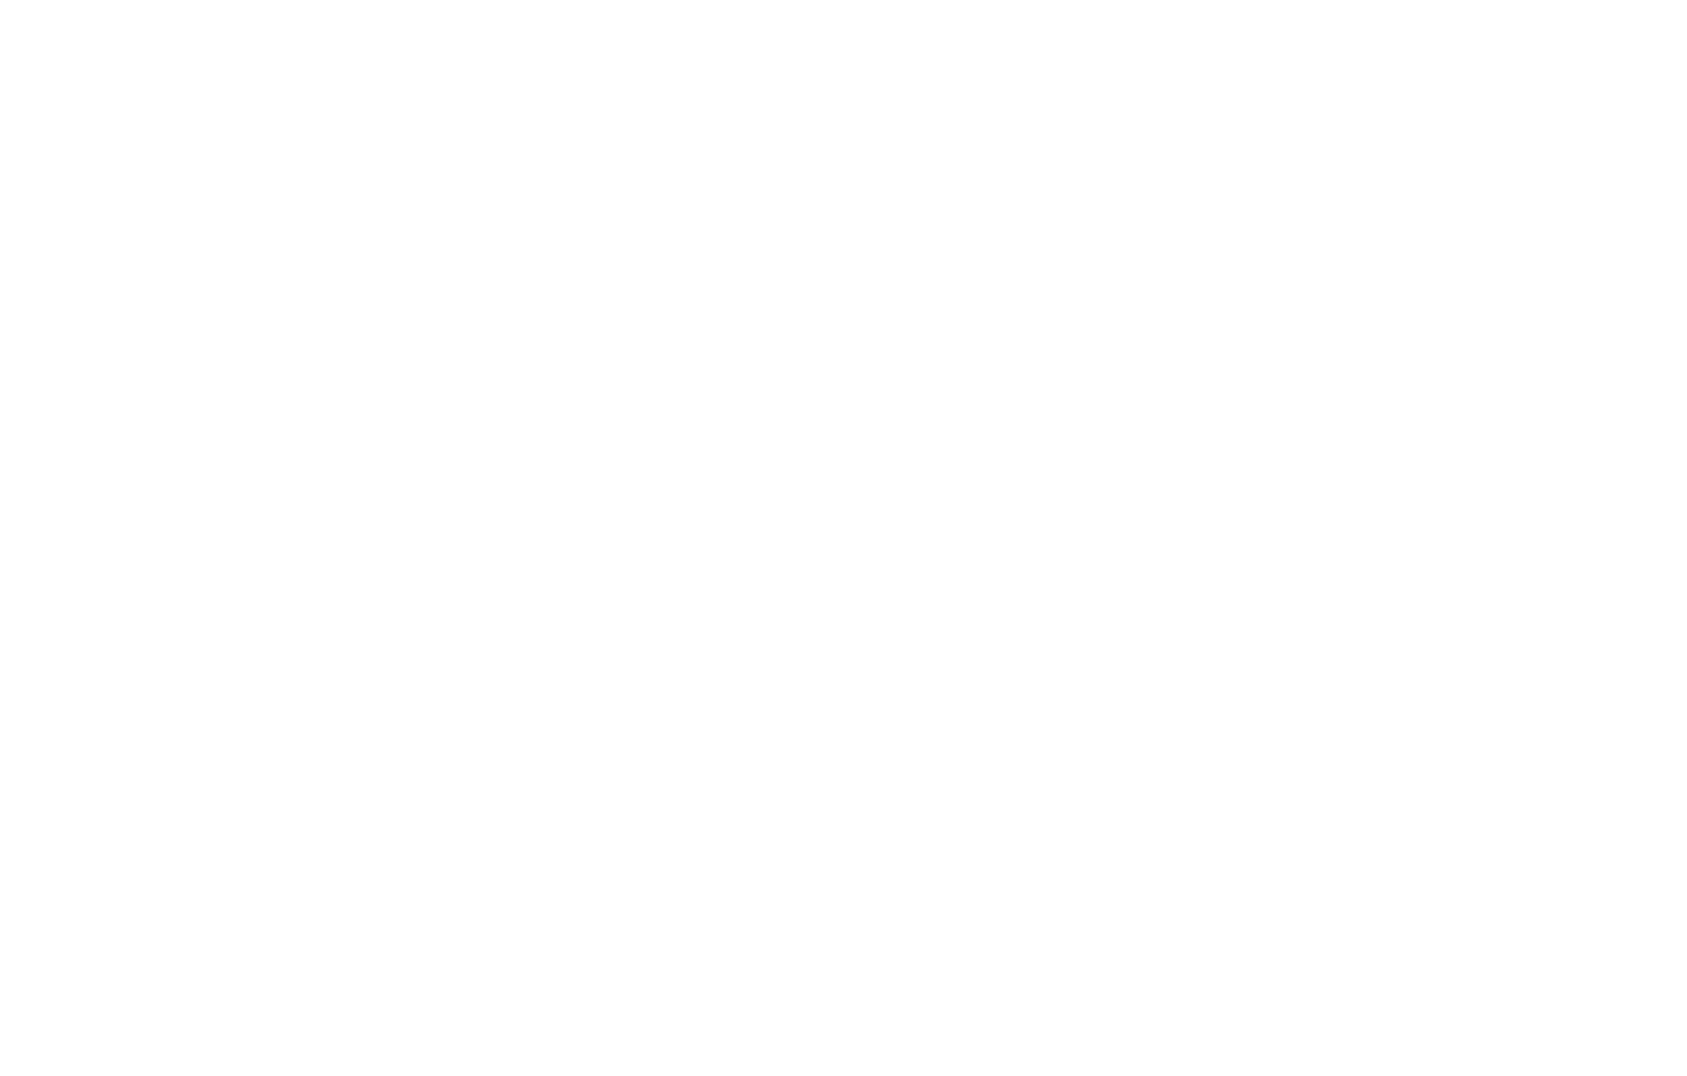

In [4]:
# Standalone academic-paper workflow flowchart.
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

FIG_DIR = "./Report/figures"
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 9,
    "axes.unicode_minus": False,
})

fig, ax = plt.subplots(figsize=(7.0, 4.4))
ax.set_xlim(0, 21)
ax.set_ylim(0, 12)
ax.axis("off")


def box(ax, x, y, w, h, text, *, dashed=False, thick=False):
    patch = FancyBboxPatch(
        (x - w / 2, y - h / 2), w, h,
        boxstyle="round,pad=0.07,rounding_size=0.10",
        facecolor="white" if dashed else "#F2F2F2",
        edgecolor="black", linewidth=1.35 if thick else 0.9,
        linestyle="--" if dashed else "-", zorder=3,
    )
    ax.add_patch(patch)
    ax.text(x, y, text, ha="center", va="center", fontsize=9,
            color="black", linespacing=1.15, zorder=4)


def arrow(ax, x1, y1, x2, y2, *, dashed=False):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2), arrowstyle="-|>,head_length=4,head_width=2.8",
        connectionstyle="arc3,rad=0", linestyle="--" if dashed else "-",
        linewidth=0.85, color="black", shrinkA=3, shrinkB=3, zorder=2,
    ))


def dotted_line(ax, points):
    xs, ys = zip(*points)
    ax.plot(xs, ys, linestyle=":", linewidth=0.8, color="black", zorder=1)

# Top row: boxes 1-5, left to right.
top_y = 9.55
box(ax, 2.0, top_y, 3.45, 2.15,
    "1. Raw AI4I 2020 data\n10,000 rows\n339 failures (3.39%)")
box(ax, 6.15, top_y, 3.75, 2.15,
    "2. Preprocessing\nDrop UDI, Product ID and\n5 failure-mode flags\nEncode Type (L/M/H = 0/1/2)\n6 inputs: Type + 5 sensors")
box(ax, 10.3, top_y, 3.55, 2.15,
    "3. Stratified split (seed 2077)\nTrain 7,000\nVal 1,500\nTest 1,500")
box(ax, 14.5, top_y, 4.0, 2.15,
    "4. Feature reduction (fit on Train only)\n9 settings: All 6, Drop Type only, ANOVA,\nPearson, Adapted Lasso, RFE,\nForward SFS, Backward SFS, PCA 95%\nk = 4")
box(ax, 18.7, top_y, 3.25, 2.15,
    "5. Screening\n9 settings × 6 classifiers = 54 runs\nscored on Val (F1)")
arrow(ax, 3.73, top_y, 4.28, top_y)
arrow(ax, 8.03, top_y, 8.53, top_y)
arrow(ax, 12.08, top_y, 12.5, top_y)
arrow(ax, 16.5, top_y, 17.08, top_y)

# Bottom row: boxes 6-9, right to left.
bottom_y = 2.05
box(ax, 18.7, bottom_y, 3.25, 1.95,
    "6. Tuning\nTop 3 candidates\nGridSearchCV, 5-fold CV\non Train")
box(ax, 14.5, bottom_y, 3.55, 1.95,
    "7. Winner selection\ntuned Top 3 compared on Val\n#1 = winner")
box(ax, 9.75, bottom_y, 4.25, 1.95,
    "8. Refit on Dev set\n(Train + Val = 8,500)\nWinner: tuned GB\nStacking: GB + GB + RF base learners\n+ Logistic Regression meta-model")
box(ax, 3.75, bottom_y, 3.8, 1.95,
    "9. Final evaluation\nTest set used once\nWinner vs Stacking", thick=True)
arrow(ax, 17.08, bottom_y, 16.28, bottom_y)
arrow(ax, 12.73, bottom_y, 11.88, bottom_y)
arrow(ax, 7.63, bottom_y, 5.65, bottom_y)
arrow(ax, 18.7, 8.48, 18.7, 3.03)

# Locked test branch, routed below box 3 and around the left side of box 8.
box(ax, 8.0, 6.35, 4.25, 0.82,
    "Test set (1,500) locked until step 9;\nnever used for selection or tuning",
    dashed=True)
arrow(ax, 10.3, 8.48, 9.65, 6.76, dashed=True)
ax.plot([8.0, 6.3, 6.3, 3.75, 3.75], [5.94, 5.94, 0.55, 0.55, 1.08],
        linestyle="--", linewidth=0.8, color="black", zorder=1)
arrow(ax, 3.75, 0.55, 3.75, 1.08, dashed=True)

# Robustness note, connected by a dotted line without an arrowhead.
box(ax, 19.0, 6.35, 3.35, 0.82,
    "Robustness check: 5 re-splits of\nthe Dev set (no Test data)", dashed=True)
dotted_line(ax, [(18.7, 8.48), (18.7, 7.25), (19.0, 6.76)])

plt.tight_layout(pad=0.15)
png_path = os.path.join(FIG_DIR, "fig1_workflow_academic.png")
fig.savefig(png_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved academic workflow flowchart -> {png_path}")